### MoE

In [48]:
import torch
from torch import nn
import torch.nn.functional as F

import math
from inspect import isfunction


MIN_EXPERT_CAPACITY = 4

# helper functions

def default(val, default_val):
    default_val = default_val() if isfunction(default_val) else default_val
    return val if val is not None else default_val

def cast_tuple(el):
    return el if isinstance(el, tuple) else (el,)

# tensor related helper functions

def top1(t):
    values, index = t.topk(k=1, dim=-1)
    values, index = map(lambda x: x.squeeze(dim=-1), (values, index))
    return values, index

def cumsum_exclusive(t, dim=-1):
    num_dims = len(t.shape)
    num_pad_dims = - dim - 1
    pre_padding = (0, 0) * num_pad_dims
    pre_slice   = (slice(None),) * num_pad_dims
    padded_t = F.pad(t, (*pre_padding, 1, 0)).cumsum(dim=dim)
    return padded_t[(..., slice(None, -1), *pre_slice)]

# pytorch one hot throws an error if there are out of bound indices.
# tensorflow, in contrast, does not throw an error
def safe_one_hot(indexes, max_length):
    max_index = indexes.max() + 1
    return F.one_hot(indexes, max(max_index + 1, max_length))[..., :max_length]

def init_(t):
    dim = t.shape[-1]
    std = 1 / math.sqrt(dim)
    return t.uniform_(-std, std)

# activations

class GELU_(nn.Module):
    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(math.sqrt(2 / math.pi) * (x + 0.044715 * torch.pow(x, 3))))

GELU = nn.GELU if hasattr(nn, 'GELU') else GELU_

# expert class

class Experts(nn.Module):
    def __init__(self,
        dim,
        num_experts = 16,
        hidden_dim = None,
        activation = GELU):
        super().__init__()

        hidden_dim = default(hidden_dim, dim * 4)
        num_experts = cast_tuple(num_experts)

        w1 = torch.zeros(*num_experts, dim, hidden_dim)
        w2 = torch.zeros(*num_experts, hidden_dim, dim)

        w1 = init_(w1)
        w2 = init_(w2)

        self.w1 = nn.Parameter(w1)
        self.w2 = nn.Parameter(w2)
        self.act = activation()

    def forward(self, x):
        hidden = torch.einsum('...nd,...dh->...nh', x, self.w1)
        hidden = self.act(hidden)
        out    = torch.einsum('...nh,...hd->...nd', hidden, self.w2)
        return out

# the below code is almost all transcribed from the official tensorflow version, from which the papers are written
# https://github.com/tensorflow/tensor2tensor/blob/master/tensor2tensor/models/research/moe.py

# gating network

class Top2Gating(nn.Module):
    def __init__(
        self,
        dim,
        num_gates,
        eps = 1e-9,
        outer_expert_dims = tuple(),
        second_policy_train = 'random',
        second_policy_eval = 'random',
        second_threshold_train = 0.2,
        second_threshold_eval = 0.2,
        capacity_factor_train = 1.25,
        capacity_factor_eval = 2.):
        super().__init__()

        self.eps = eps
        self.num_gates = num_gates
        self.w_gating = nn.Parameter(torch.randn(*outer_expert_dims, dim, num_gates))

        self.second_policy_train = second_policy_train
        self.second_policy_eval = second_policy_eval
        self.second_threshold_train = second_threshold_train
        self.second_threshold_eval = second_threshold_eval
        self.capacity_factor_train = capacity_factor_train
        self.capacity_factor_eval = capacity_factor_eval

    def forward(self, x, importance = None):
        *_, b, group_size, dim = x.shape
        num_gates = self.num_gates

        if self.training:
            policy = self.second_policy_train
            threshold = self.second_threshold_train
            capacity_factor = self.capacity_factor_train
        else:
            policy = self.second_policy_eval
            threshold = self.second_threshold_eval
            capacity_factor = self.capacity_factor_eval

        raw_gates = torch.einsum('...bnd,...de->...bne', x, self.w_gating)
        raw_gates = raw_gates.softmax(dim=-1)

        # FIND TOP 2 EXPERTS PER POSITON
        # Find the top expert for each position. shape=[batch, group]

        gate_1, index_1 = top1(raw_gates)
        mask_1 = F.one_hot(index_1, num_gates).float()
        density_1_proxy = raw_gates

        if importance is not None:
            equals_one_mask = (importance == 1.).float()
            mask_1 *= equals_one_mask[..., None]
            gate_1 *= equals_one_mask
            density_1_proxy = density_1_proxy * equals_one_mask[..., None]
            del equals_one_mask

        gates_without_top_1 = raw_gates * (1. - mask_1)

        gate_2, index_2 = top1(gates_without_top_1)
        mask_2 = F.one_hot(index_2, num_gates).float()

        if importance is not None:
            greater_zero_mask = (importance > 0.).float()
            mask_2 *= greater_zero_mask[..., None]
            del greater_zero_mask

        # normalize top2 gate scores
        denom = gate_1 + gate_2 + self.eps
        gate_1 /= denom
        gate_2 /= denom

        # BALANCING LOSSES
        # shape = [batch, experts]
        # We want to equalize the fraction of the batch assigned to each expert
        density_1 = mask_1.mean(dim=-2)
        # Something continuous that is correlated with what we want to equalize.
        density_1_proxy = density_1_proxy.mean(dim=-2)
        loss = (density_1_proxy * density_1).mean() * float(num_gates ** 2)

        # Depending on the policy in the hparams, we may drop out some of the
        # second-place experts.
        if policy == "all":
            pass
        elif policy == "none":
            mask_2 = torch.zeros_like(mask_2)
        elif policy == "threshold":
            mask_2 *= (gate_2 > threshold).float()
        elif policy == "random":
            probs = torch.zeros_like(gate_2).uniform_(0., 1.)
            mask_2 *= (probs < (gate_2 / max(threshold, self.eps))).float().unsqueeze(-1)
        else:
            raise ValueError(f"Unknown policy {policy}")

        # Each sequence sends (at most?) expert_capacity positions to each expert.
        # Static expert_capacity dimension is needed for expert batch sizes
        expert_capacity = min(group_size, int((group_size * capacity_factor) / num_gates))
        expert_capacity = max(expert_capacity, MIN_EXPERT_CAPACITY)
        expert_capacity_f = float(expert_capacity)

        # COMPUTE ASSIGNMENT TO EXPERTS
        # [batch, group, experts]
        # This is the position within the expert's mini-batch for this sequence
        position_in_expert_1 = cumsum_exclusive(mask_1, dim=-2) * mask_1
        # Remove the elements that don't fit. [batch, group, experts]
        mask_1 *= (position_in_expert_1 < expert_capacity_f).float()
        # [batch, experts]
        # How many examples in this sequence go to this expert
        mask_1_count = mask_1.sum(dim=-2, keepdim=True)
        # [batch, group] - mostly ones, but zeros where something didn't fit
        mask_1_flat = mask_1.sum(dim=-1)
        # [batch, group]
        position_in_expert_1 = position_in_expert_1.sum(dim=-1)
        # Weight assigned to first expert.  [batch, group]
        gate_1 *= mask_1_flat

        position_in_expert_2 = cumsum_exclusive(mask_2, dim=-2) + mask_1_count
        position_in_expert_2 *= mask_2
        mask_2 *= (position_in_expert_2 < expert_capacity_f).float()
        mask_2_flat = mask_2.sum(dim=-1)

        position_in_expert_2 = position_in_expert_2.sum(dim=-1)
        gate_2 *= mask_2_flat
        
        # [batch, group, experts, expert_capacity]
        combine_tensor = (
            gate_1[..., None, None]
            * mask_1_flat[..., None, None]
            * F.one_hot(index_1, num_gates)[..., None]
            * safe_one_hot(position_in_expert_1.long(), expert_capacity)[..., None, :] +
            gate_2[..., None, None]
            * mask_2_flat[..., None, None]
            * F.one_hot(index_2, num_gates)[..., None]
            * safe_one_hot(position_in_expert_2.long(), expert_capacity)[..., None, :]
        )

        dispatch_tensor = combine_tensor.bool().to(combine_tensor)
        return dispatch_tensor, combine_tensor, loss

# plain mixture of experts

class MoE(nn.Module):
    def __init__(self,
        dim,
        num_experts = 16,
        hidden_dim = None,
        activation = nn.ReLU,
        second_policy_train = 'random',
        second_policy_eval = 'random',
        second_threshold_train = 0.2,
        second_threshold_eval = 0.2,
        capacity_factor_train = 1.25,
        capacity_factor_eval = 2.,
        loss_coef = 1e-2,
        experts = None):
        super().__init__()

        self.num_experts = num_experts

        gating_kwargs = {'second_policy_train': second_policy_train, 'second_policy_eval': second_policy_eval, 'second_threshold_train': second_threshold_train, 'second_threshold_eval': second_threshold_eval, 'capacity_factor_train': capacity_factor_train, 'capacity_factor_eval': capacity_factor_eval}
        self.gate = Top2Gating(dim, num_gates = num_experts, **gating_kwargs)
        self.experts = default(experts, lambda: Experts(dim, num_experts = num_experts, hidden_dim = hidden_dim, activation = activation))
        self.loss_coef = loss_coef

    def forward(self, inputs, **kwargs):
        b, n, d, e = *inputs.shape, self.num_experts
        dispatch_tensor, combine_tensor, loss = self.gate(inputs)
        expert_inputs = torch.einsum('bnd,bnec->ebcd', inputs, dispatch_tensor)

        # Now feed the expert inputs through the experts.
        orig_shape = expert_inputs.shape
        expert_inputs = expert_inputs.reshape(e, -1, d)
        expert_outputs = self.experts(expert_inputs)
        expert_outputs = expert_outputs.reshape(*orig_shape)

        output = torch.einsum('ebcd,bnec->bnd', expert_outputs, combine_tensor)
        return output, loss * self.loss_coef


In [49]:
import torch
import torch.nn as nn

class SequenceModelWithMoE(nn.Module):
    def __init__(self, 
                 vocab_size, 
                 embedding_dim=128, 
                 sequence_length=20, 
                 num_experts=8, 
                 num_classes=10):
        super().__init__()
        
        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        
        # Mixture of Experts layer
        self.moe = MoE(
            dim=embedding_dim,
            num_experts=num_experts,
            hidden_dim=embedding_dim * 4,  # Typical MLP hidden dimension
            activation=nn.GELU,
            loss_coef=0.01  # Small coefficient for the load balancing loss
        )
        
        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(embedding_dim, num_classes),
            nn.LogSoftmax(dim=-1)
        )
    
    def forward(self, x):
        # Embed the input sequence
        embedded = self.embedding(x)
        
        # Pass through Mixture of Experts
        moe_output, moe_loss = self.moe(embedded)
        
        # Classification
        logits = self.classifier(moe_output.mean(dim=1))
        
        return logits, moe_loss

# Example usage
def example_usage():
    # Hyperparameters
    vocab_size = 1000
    batch_size = 32
    sequence_length = 20
    num_classes = 10

    # Create model
    model = SequenceModelWithMoE(
        vocab_size=vocab_size, 
        num_experts=8, 
        num_classes=num_classes
    )

    # Random input sequence
    input_sequences = torch.randint(0, vocab_size, (batch_size, sequence_length))

    # Forward pass
    logits, moe_loss = model(input_sequences)

    # Training step (conceptual example)
    criterion = nn.NLLLoss()
    target = torch.randint(0, num_classes, (batch_size,))
    
    classification_loss = criterion(logits, target)
    total_loss = classification_loss + moe_loss

    print(f"Logits shape: {logits.shape}")
    print(f"Classification Loss: {classification_loss.item()}")
    print(f"MoE Load Balancing Loss: {moe_loss.item()}")

# Run the example
if __name__ == '__main__':
    example_usage()

Logits shape: torch.Size([32, 10])
Classification Loss: 2.2872154712677
MoE Load Balancing Loss: 0.013497753068804741


In [46]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ExpertFFN(nn.Module):
    """Individual expert feed-forward network"""
    def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.1):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, hidden_dim)
        self.layer2 = nn.Linear(hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.GELU()

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.dropout(x)
        x = self.layer2(x)
        return x

class GatingNetwork(nn.Module):
    """Network to determine routing of inputs to experts"""
    def __init__(self, input_dim, num_experts, top_k=2):
        super().__init__()
        self.gate = nn.Linear(input_dim, num_experts)
        self.top_k = top_k

    def forward(self, x):
        # Calculate gate scores
        gate_scores = self.gate(x)
        
        # Get top-k gate scores and indices
        top_scores, top_indices = torch.topk(gate_scores, self.top_k, dim=-1)
        
        # Normalize scores using softmax
        gate_weights = F.softmax(top_scores, dim=-1)
        
        return gate_weights, top_indices

class MoEFFN(nn.Module):
    """Complete Mixture of Experts feed-forward block"""
    def __init__(
        self,
        input_dim,
        hidden_dim,
        output_dim,
        num_experts=8,
        top_k=2,
        dropout=0.1,
        capacity_factor=1.0
    ):
        super().__init__()
        
        self.num_experts = num_experts
        self.top_k = top_k
        self.capacity_factor = capacity_factor
        
        # Initialize experts
        self.experts = nn.ModuleList([
            ExpertFFN(input_dim, hidden_dim, output_dim, dropout)
            for _ in range(num_experts)
        ])
        
        # Initialize gating network
        self.gate = GatingNetwork(input_dim, num_experts, top_k)
        
        # Layer norm for input
        self.layer_norm = nn.LayerNorm(input_dim)
        
    def _compute_capacity(self, batch_size):
        """Compute capacity of each expert based on batch size"""
        capacity = int(self.capacity_factor * batch_size * self.top_k / self.num_experts)
        return max(1, capacity)  # Ensure at least 1
        
    def forward(self, x):
        """
        Args:
            x: Input tensor of shape [batch_size, seq_len, input_dim]
        Returns:
            Output tensor of shape [batch_size, seq_len, output_dim]
        """
        original_shape = x.shape
        batch_size, seq_len, input_dim = original_shape
        
        # Reshape input for expert processing
        x = x.view(-1, input_dim)  # [batch_size * seq_len, input_dim]
        
        # Apply layer norm
        normalized_x = self.layer_norm(x)
        
        # Get expert assignments and weights from gate
        gate_weights, expert_indices = self.gate(normalized_x)
        
        # Initialize output tensor
        final_output = torch.zeros(
            (batch_size * seq_len, self.experts[0].layer2.out_features),
            device=x.device
        )
        
        # Compute expert capacity
        capacity = self._compute_capacity(batch_size * seq_len)
        
        # Process inputs through experts
        for expert_idx in range(self.num_experts):
            # Find which inputs are routed to this expert
            expert_mask = (expert_indices == expert_idx).any(dim=-1)
            
            # Skip if no inputs for this expert
            if not expert_mask.any():
                continue
                
            # Get expert inputs
            expert_inputs = normalized_x[expert_mask]
            
            # Apply capacity limit with safer indexing
            if len(expert_inputs) > capacity:
                # Use torch.randperm more safely
                perm_indices = torch.randperm(len(expert_inputs), device=expert_inputs.device)[:capacity]
                expert_inputs = expert_inputs[perm_indices]
                
                # Update expert mask to reflect selected inputs
                original_indices = torch.nonzero(expert_mask).squeeze()
                selected_original_indices = original_indices[perm_indices]
                
                # Recreate expert mask with only selected inputs
                new_expert_mask = torch.zeros_like(expert_mask, dtype=torch.bool)
                new_expert_mask[selected_original_indices] = True
                expert_mask = new_expert_mask
            
            # Process inputs through expert
            expert_output = self.experts[expert_idx](expert_inputs)
            
            # Compute expert weights safely
            try:
                # Get corresponding gate weights
                expert_position = (expert_indices[expert_mask] == expert_idx).nonzero()
                if len(expert_position) > 0:
                    expert_position = expert_position.squeeze(-1)
                    current_gate_weights = gate_weights[expert_mask][torch.arange(len(expert_position)), expert_position]
                    
                    # Add weighted output to final output
                    final_output[expert_mask] += expert_output * current_gate_weights.unsqueeze(-1)
            except Exception as e:
                print(f"Error processing expert {expert_idx}: {e}")
                # Fallback: use unweighted output
                final_output[expert_mask] += expert_output
        
        # Reshape output back to original dimensions
        output = final_output.view(original_shape[0], original_shape[1], -1)
        
        return output

def create_moe_ffn(
    input_dim=512,
    hidden_dim=2048,
    output_dim=512,
    num_experts=8,
    top_k=2,
    dropout=0.1,
    capacity_factor=1.0
):
    """Helper function to create a MoE FFN block with default parameters"""
    return MoEFFN(
        input_dim=input_dim,
        hidden_dim=hidden_dim,
        output_dim=output_dim,
        num_experts=num_experts,
        top_k=top_k,
        dropout=dropout,
        capacity_factor=capacity_factor
    )

# Or customize the parameters
custom_moe = create_moe_ffn(
    input_dim=16,
    hidden_dim=3072,
    output_dim=768,
    num_experts=16,
    top_k=2
)

# Forward pass
batch_size, seq_len, input_dim = 2, 50, 16
x = torch.randn(batch_size, seq_len, input_dim)
output = custom_moe(x)

Error processing expert 0: shape mismatch: indexing tensors could not be broadcast together with shapes [9], [9, 2]
Error processing expert 1: output with shape [2, 768] doesn't match the broadcast shape [2, 2, 768]
Error processing expert 2: shape mismatch: indexing tensors could not be broadcast together with shapes [12], [12, 2]
Error processing expert 3: shape mismatch: indexing tensors could not be broadcast together with shapes [12], [12, 2]
Error processing expert 4: shape mismatch: indexing tensors could not be broadcast together with shapes [6], [6, 2]
Error processing expert 5: shape mismatch: indexing tensors could not be broadcast together with shapes [11], [11, 2]
Error processing expert 6: shape mismatch: indexing tensors could not be broadcast together with shapes [12], [12, 2]
Error processing expert 7: shape mismatch: indexing tensors could not be broadcast together with shapes [12], [12, 2]
Error processing expert 8: shape mismatch: indexing tensors could not be broad

### image process

PROOF OF WORKING CONCAT, DIFF KERNEL

In [ ]:
import torch
from NKD_models import NKD_concat_kernel_learn, NKD_rbf_feat_learn
from utils import img2channel_list, unpad

class config:
    def __init__(self):
        pass
args = config()

args.residual_depth = 2
args.proj_depth = 2
args.latent_dim = 512
args.blind = True
args.in_channel = 3
args.patch_rad = 1
args.window_rad = 2
args.latent_channel_dim = 10
device = 'cpu'
self = NKD_concat_kernel_learn(args, device)

batch = 10
patch_rad = 1
in_channel, height, width = 3, 2*(patch_rad+ args.window_rad)+1, 2*(patch_rad+ args.window_rad)+1
pad = 0

patch_size = patch_rad*2 + 1
img = torch.rand(batch, in_channel, height, width)
# print('img',img, img.shape)

print(self(img).shape)
# ## _process_input
# x = self._extract_patch_vector(img)
# print("x",x, x.shape)
# x = img2channel_list(x)
# print("x",x, x.shape)

# ## _get_activation
# x1 = self.in_layer(x)
# # print('x1', x1)
# for i in range(self.residual_depth):
#     x1 = x1 + self.in_residual[i](x1)
#     x1 = self.in_norm[i](x1)
# x2 = self._diff_sq_central_pixel(x1)
# # print('x3', x2)
# x3 = self.proj(x2)
# x4 = self.out(x3)
# guide_weights = torch.exp(x4/(-2))

# # print("guide_weights",guide_weights,guide_weights.shape)
# normalizing_factor = torch.sum(guide_weights, dim=1)
# # print("guide_weights",normalizing_factor,normalizing_factor.shape)
# inp = img2channel_list(unpad(img, self.patch_rad, self.patch_rad))
# print("inp",inp, inp.shape)

# out = torch.sum((guide_weights*inp), dim=1)/normalizing_factor
# print("out",out, out.shape)
# out = out.reshape(batch, self.in_channel)


torch.Size([10, 3])


LINEAR TO IMAGE CALCULATIONS

In [21]:
import torch
import torch.nn as nn
from utils import channel_list2img, img2channel_list

In [22]:
batch = 1
patch_rad = 1
in_channel, height, width = 1, 8, 8
out_channel = 2
pad = 0

patch_size = patch_rad*2 + 1
parameters = nn.Linear(in_channel*patch_size*patch_size,out_channel)
parameters_linear = parameters.weight
parameters_bias = parameters.bias

In [23]:
parameters_linear.shape

torch.Size([2, 9])

In [3]:
n = 3
N = n**2
inp = torch.randn(batch, N, patch_size*patch_size*in_channel)
print(inp.shape, parameters_linear.shape)
print(parameters(inp))
print(img2channel_list(torch.functional.F.conv2d(channel_list2img(inp,n,n),parameters_linear.reshape(out_channel,-1, 1, 1),bias=parameters_bias)))

torch.Size([1, 9, 9]) torch.Size([2, 9])
tensor([[[-0.0227,  0.0279],
         [ 0.4399, -0.2632],
         [-0.9269,  0.1603],
         [-0.9829,  0.2464],
         [-0.2173,  0.5890],
         [-0.9113,  0.4607],
         [ 1.1682, -0.2360],
         [-0.2408, -0.0198],
         [-1.0832,  0.1265]]], grad_fn=<ViewBackward0>)
tensor([[[-0.0227,  0.0279],
         [ 0.4399, -0.2632],
         [-0.9269,  0.1603],
         [-0.9829,  0.2464],
         [-0.2173,  0.5890],
         [-0.9113,  0.4607],
         [ 1.1682, -0.2360],
         [-0.2408, -0.0198],
         [-1.0832,  0.1265]]], grad_fn=<ViewBackward0>)


In [4]:
batch = 1
patch_rad = 1
in_channel, height, width = 1, 8, 8
out_channel = 2
pad = 0

patch_size = patch_rad*2 + 1
parameters = nn.LayerNorm(in_channel*patch_size*patch_size)
parameters_linear = parameters.weight
parameters_bias = parameters.bias

In [7]:
n = 3
N = n**2
inp = torch.randn(batch, N, patch_size*patch_size*in_channel)
print(inp.shape, parameters_linear.shape)
print(parameters(inp)==torch.functional.F.layer_norm(inp,(patch_size*patch_size*in_channel,),parameters_linear,bias=parameters_bias))

torch.Size([1, 9, 9]) torch.Size([9])
tensor([[[True, True, True, True, True, True, True, True, True],
         [True, True, True, True, True, True, True, True, True],
         [True, True, True, True, True, True, True, True, True],
         [True, True, True, True, True, True, True, True, True],
         [True, True, True, True, True, True, True, True, True],
         [True, True, True, True, True, True, True, True, True],
         [True, True, True, True, True, True, True, True, True],
         [True, True, True, True, True, True, True, True, True],
         [True, True, True, True, True, True, True, True, True]]])


In [10]:
import torch
import torch.nn as nn
from utils import channel_list2img, img2channel_list, img2Dshift, Box
from NKD_models import NKD_denoisers


In [2]:
class NKD_concat_kernel_learn(NKD_denoisers):
    def __init__(self): 
        super().__init__()
        self.device = 'cpu'
        self.residual_depth = 2
        self.proj_depth = 2
        self.sigma = 1
        self.blind = True
        self.latent_dim = 1024
        self.patch_rad = 2
        patch_size = self.patch_rad * 2 + 1

        self.window_rad = 7
        self.in_channel = 1

        if self.blind:
            in_dim=2*self.in_channel*patch_size*patch_size
        else:
            in_dim=2*(self.in_channel+1)*patch_size*patch_size
            
        self.in_layer = nn.Linear(in_features=in_dim,out_features=self.latent_dim)
        self.in_residual = nn.ModuleList([
            nn.Sequential(
                nn.Linear(in_features=self.latent_dim,out_features=self.latent_dim*2),
                nn.LeakyReLU(),
                nn.Linear(in_features=self.latent_dim*2,out_features=self.latent_dim),
            )
            for _ in range(self.residual_depth)
        ])
        self.in_norm = nn.ModuleList([
            nn.LayerNorm(self.latent_dim)
            for _ in range(self.residual_depth)
        ])
        # self.in_proj = nn.Linear(in_features=in_dim,out_features=latent_dim)

        self.proj = nn.Sequential(*[
            nn.Sequential(
                nn.Linear(in_features=self.latent_dim//(2**i),out_features=self.latent_dim//(2**(i+1))),
                nn.LayerNorm(self.latent_dim//(2**(i+1))),
                nn.LeakyReLU(),
            )
            for i in range(self.proj_depth)
        ])
        self.out = nn.Linear(in_features=self.latent_dim//(2**(self.proj_depth)),out_features=self.in_channel)
    
    def pre_feature(self,inp_img):
        x = self._extract_patch_vector(inp_img)
        return x
    
    def compute_activation(self,inp_img, t):
        x1, x2 = (torch.cat((inp_img, t), dim=1), torch.cat((t, inp_img), dim=1))
        # print("x2",x2.shape)
        x = torch.cat((x1,x2), dim=-1)
        x = self._get_activation_img(x)
        x1,x2 = torch.chunk(x, chunks=2, dim=-1)
        # print('x1', x1)
        return torch.exp((x1+x2)/(-2*self.sigma))
    
    def NLM(self, input_image, guide_features):
        window_rad = self.window_rad
        patch_rad = self.patch_rad
        # sigma = self.sigma
        
        input_image = input_image.to(torch.float32)
        guide = self.pre_feature(
            torch.nn.functional.pad(guide_features, (patch_rad, patch_rad, patch_rad, patch_rad), mode='circular')
        )
        _, _, height, width = input_image.shape

        U = torch.zeros_like(input_image, dtype=torch.float64, device=input_image.device)  # To hold denoised image
        Z = torch.zeros_like(input_image, dtype=torch.float64, device=input_image.device)  # To hold accumulated weights

        padded_v = torch.nn.functional.pad(input_image, (window_rad, window_rad, window_rad, window_rad), mode='circular')

        # normalization_factor = -(sigma * sigma)

        for dx in range(-window_rad, window_rad + 1):
            for dy in range(-window_rad, window_rad + 1):
                t = img2Dshift(guide, dx, dy)
                activation = self.compute_activation(guide, t)
                hat = Box(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)

                w = hat * activation
                v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
                U = U + w * v
                Z = Z + w
        U = U / Z
        return U.to(torch.float32)  # U = Denoised image

    def _concat_patch_central_pixel(self, inp, t = None, img=False):
        b, c, h, w = inp.shape
        center = (inp[:,:,h//2,w//2])[:,:,None,None].expand_as(inp)
        central_pixel = img2channel_list(center)
        channel_list = img2channel_list(inp)
        return (torch.cat((channel_list,central_pixel), dim=-1), 
                torch.cat((central_pixel,channel_list), dim=-1))

    def _get_activation(self, x):
        # print('xa', x.shape)
        x = self.in_layer(x)
        # print('xb', x.shape)
        for i in range(self.residual_depth):
            x = x + self.in_residual[i](x)
            x = self.in_norm[i](x)
            # print('xc', x)
        x = self.proj(x)
        print('xd', x.shape)
        x = self.out(x)
        print('xe', x.shape)
        x1,x2 = torch.chunk(x, chunks=2, dim=1)
        print('x1', x1.shape)
        return torch.exp((x1+x2)/(-2*self.sigma))

    def _get_activation_img(self, x):
        # print('xa', x.shape)
        x = linear_img_fwd(x, self.in_layer)
        # print('xb', x.shape)
        for i in range(self.residual_depth):
            x = x + blk_img_fwd(x, self.in_residual[i])
            x = norm_img_fwd(x, self.in_norm[i])
            # print('xc', x)
        x = blk_img_fwd(x, self.proj)
        # print('xd', x.shape)
        x = linear_img_fwd(x, self.out)
        # print('xe', x.shape)
        return x

    def _process_input(self, inp):
        # print("inp",inp.shape)
        x = self._extract_patch_vector(inp)
        # print("x",x.shape)
        x1, x2 = self._concat_patch_central_pixel(x)
        # print("x1",x1.shape)
        # print("x2",x2.shape)
        inp = torch.cat((x1,x2), dim=1)
        # print("inp",inp.shape)
        return inp


In [3]:
a = NKD_concat_kernel_learn()

def linear_img_fwd(img, parameters: nn.Linear):
    out_channel, in_channel = parameters.weight.shape
    parameters_linear = (parameters.weight).reshape(out_channel,in_channel, 1, 1)
    parameters_bias = parameters.bias
    return torch.functional.F.conv2d(
        img,parameters_linear,
        bias=parameters_bias,
    )

def norm_img_fwd(img, parameters: nn.LayerNorm):
    parameters_linear = parameters.weight
    parameters_bias = parameters.bias
    c, h, w = img.shape[-3:]
    inp = img2channel_list(img)
    out = torch.functional.F.layer_norm(inp,(c,),parameters_linear,bias=parameters_bias)
    return channel_list2img(out, h, w)

def blk_img_fwd(x, blk):
    for i in blk:
        if isinstance(i, nn.Linear):
            x = linear_img_fwd(x, i)
        elif isinstance(i, nn.LayerNorm):
            x = norm_img_fwd(x, i)
        elif isinstance(i, nn.Sequential):
            x = blk_img_fwd(x, i)
        else:
            x = i(x)
    return x

# isinstance(a.proj, nn.Sequential)
inp = torch.randn(1,8, 50)
inp_x, inp_y = torch.chunk(inp,2, dim=1)

img_inp = torch.cat((channel_list2img(inp_x, 2, 2), channel_list2img(inp_y, 2, 2)), dim=-1)

out = a._get_activation_img(img_inp)
out2 = a._get_activation(inp)
print((img2channel_list(out)==out2).all())

xb torch.Size([1, 1024, 2, 4])
xd torch.Size([1, 256, 2, 4])
xe torch.Size([1, 1, 2, 4])
xd torch.Size([1, 8, 256])
xe torch.Size([1, 8, 1])
x1 torch.Size([1, 4, 1])
tensor(True)


In [31]:
(img2channel_list(out)==out2).all()

tensor(True)

In [1]:
import numpy as np

def kernel_mask(kernel_shape, input_shape):
    """
    Convert a 2D convolution kernel to its equivalent linear matrix form.
    
    Parameters:
    -----------
    kernel : numpy.ndarray
        2D convolution kernel
    input_shape : tuple
        Shape of the input image (height, width)
        
    Returns:
    --------
    numpy.ndarray
        Linear matrix that performs the same operation as the convolution kernel
    """
    k_h, k_w = kernel_shape
    i_h, i_w = input_shape
    
    # Output dimensions after convolution
    out_h = i_h - k_h + 1
    out_w = i_w - k_w + 1
    
    # Initialize the matrix
    matrix = np.zeros((out_h * out_w, i_h * i_w))
    
    # Fill the matrix
    for i in range(out_h):
        for j in range(out_w):
            # Current output position
            row = i * out_w + j
            
            # Fill in the kernel values
            for ki in range(k_h):
                for kj in range(k_w):
                    # Input image position
                    im_i = i + ki
                    im_j = j + kj
                    col = im_i * i_w + im_j
                    
                    # Set the kernel value
                    matrix[row, col] = 1
    
    return matrix

# Create a simple 3x3 kernel
kernel_shape = (2,2)

# Define input image shape
input_shape = (4, 4)

# Convert to matrix form
matrix = kernel_mask(kernel_shape, input_shape)

### PLOT loss

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import torch


In [8]:
def path_plots(state_dict: dict, window_size: int = 23, z: int = 1, lent=5000):
    plt.figure(figsize=(12, 8), dpi=300)
    for title in state_dict.keys():
        print(title)
        path = f'/home/aditya/NKD/{state_dict[title]}/training_log.txt'
        values = []
        moving_avg = []
        std_dev = []
        with open(path, 'r') as file:
            for line in file:
                parts = line.strip().split(',')
                value = float(parts[1])
                values.append(round(value, 8))

        values = values[:lent]
        # Calculate moving average
        moving_avg = []
        prev_mean = None
        for i in range(len(values)-window_size):
            if i == 0:
                prev_mean = np.mean(values[i:i+window_size])
            else:
                prev_mean = prev_mean+(values[i+window_size]-values[i-1])/window_size
            moving_avg.append(-np.log10(prev_mean))
        # moving_avg = [-np.log10(np.mean(values[i-window_size+1:i+1])) for i in range(window_size-1, len(values))]
        # std_dev = [z*np.std(-np.log10(values[i-window_size+1:i+1])) for i in range(window_size-1, len(values))]
        plt.plot(range(window_size, len(values)), moving_avg, label=title, linewidth=1)
        # plt.fill_between(range(window_size-1, len(values)), 
        #                 [m - s for m, s in zip(moving_avg, std_dev)], 
        #                 [m + s for m, s in zip(moving_avg, std_dev)],
        #                 alpha=0.5)
    

In [9]:
state_dict = {
    'kernel function learn: concatenate patchs, patch size = 3' : 'output__concat_kl_1711024_25_130_30_0208041206',
    'kernel function learn: concatenate patchs, patch size = 5' : 'output__concat_kl_2711024_25_130_30_0208142343',
    # 'kernel function learn: concatenate patchs, patch size = 9' : 'output__concat_kl_4711024_22_130_30_0205165452',
    'kernel function learn: concatenate patchs, patch size = 11' : 'output__concat_kl_5711024_25_130_30_0209001822',
}
# state_dict = {
#     # 'RBG feature learning, patch size = 9' : 'output_rbf_471102410_25_130_30_0206124720',
#     'kernel function learn: concatenate patchs, patch size = 9' : 'output__concat_kl_1711024_25_130_30_0208041206',
#     # 'kernel function learn: diff. sq. of patch features, patch size = 9' : 'output_diff_kl_4711024_25_130_30_0205211905',
# }
value = 3
path_plots(state_dict, window_size=10000, lent=50000)
# plt.plot([value for _ in range(5000)], '--', label=f'value={value}', linewidth=1)
# plt.title(r'$\mathcal{C}ombined$ $\mathcal{C}hecker$ $\mathcal{P}attern$ $\mathcal{M}atrices$ $(n \times n)$', fontsize=14)
# plt.axis('off')
plt.title(r'negative log Loss($\uparrow$) v/s Iterations($\sigma$ = 30)', fontsize=18)
plt.xlabel('Iterations', fontsize=14)
plt.ylabel('negative log Loss', fontsize=14)
plt.legend(fontsize=5)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('loss_comparison.png', dpi=300)
plt.close()

kernel function learn: concatenate patchs, patch size = 3
kernel function learn: concatenate patchs, patch size = 5
kernel function learn: concatenate patchs, patch size = 11


In [1]:
# from dataset_loader_kernel import TrainingDataset, DataLoader

# batch = 124
# patch_rad = 1
# window_rad = 5
# in_channel, height, width = 3, 2*(patch_rad+window_rad)+1, 2*(patch_rad+window_rad)+1

# train_dataset = TrainingDataset('./data/train', 2*(patch_rad+window_rad)+1, 'rgb', 15, 15, imgs_per_epoch=1, no_patches=128)



Loading training images...
Loaded 400 images from BSD400
Total loaded 400 images from: BSD400
Loaded 400 images for training


In [2]:
train_loader = DataLoader(train_dataset, 1)
for i, d in enumerate(train_loader):
    print(len(d))
    # break

3


In [1]:
import torch
import torch.nn as nn

def extract_random_patches(images, patch_rad, factor=None, no_of_patches=None):
    if factor==None and no_of_patches==None:
        raise ValueError('input one out of factor or no_of patches values')
    elif factor!=None and no_of_patches!=None:
        raise ValueError('input one out of factor or no_of patches values')

    N, C, H, W = images.shape
    patches = []

    for img_idx in range(N):
        img = images[img_idx]
        
        # Total number of pixels and 30% selection
        total_pixels = H * W
        if factor != None:
            num_points = int(factor * total_pixels)
        else:
            num_points = no_of_patches

        # Randomly select points
        y_coords = torch.randint(patch_rad, H - patch_rad, (num_points,))
        x_coords = torch.randint(patch_rad, W - patch_rad, (num_points,))
        
        # Extract patches
        img_patches = []
        for y, x in zip(y_coords, x_coords):
            patch = img[:, y - patch_rad:y + patch_rad + 1, x - patch_rad:x + patch_rad + 1]
            img_patches.append(patch)
        
        patches.append(torch.stack(img_patches))
    
    return torch.stack(patches).reshape(-1, C, 2*(patch_rad)+1, 2*(patch_rad)+1)

def extract_patch_vector(inp, patch_s):
    batch, channel, _, _ = inp.shape
    t = torch.zeros(channel*patch_s*patch_s, channel, patch_s, patch_s)
    count=0
    for c in range(channel):
        for i in range(patch_s):
            for j in range(patch_s):
                t[count,c,i,j] = 1
                count+=1

    return torch.functional.F.conv2d(inp, t)#.reshape(batch, -1, channel*patch_s*patch_s)


In [3]:
# class Residual_layer(nn.Module):
#     def __init__(self, in_dim, latent_dim):
#         self.layer = nn.Sequential(
#             nn.Conv2d(in_channels=in_dim,out_channels=latent_dim,kernel_size=1,stride=1,padding=0),
#             nn.LeakyReLU(),
#             nn.Conv2d(in_channels=latent_dim,out_channels=in_dim,kernel_size=1,stride=1,padding=0),
#         )
#     def forward(self, inp):
#         return inp + self.layer(inp)

# def get_conv_layer(in_dim, latent_dim):
#     return nn.Sequential(
#         nn.Conv2d(in_channels=in_dim,out_channels=latent_dim,kernel_size=1,stride=1,padding=0),
#         nn.LeakyReLU(),
#         nn.Conv2d(in_channels=latent_dim,out_channels=in_dim,kernel_size=1,stride=1,padding=0),
#     )
    
# def get_lin_layer(in_dim, latent_dim):
#     return nn.Sequential(
#         nn.Linear(in_features=in_dim,out_features=latent_dim),
#         nn.LeakyReLU(),
#         nn.Linear(in_features=latent_dim,out_features=in_dim),
#     )
# class NKD_kernel_conv(nn.Module):
#     def __init__(self, patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind=False, no_residual=2, denoiser='NLM'): 
#         super(NKD_kernel_layers_v3).__init__()
#         self.device = device
#         self.no_residual = no_residual
#         self.sigma = 1
#         self.blind = blind
#         self.latent_dim = latent_dim
#         self.l = latent_channel_dim
#         self.patch_rad = patch_rad
#         patch_size = patch_rad * 2 + 1

#         self.window_rad = window_rad
#         self.in_channel = in_channel

#         if blind:
#             in_dim=2*in_channel*patch_size*patch_size
#         else:
#             in_dim=2*(in_channel+1)*patch_size*patch_size
    
#         self.in_residual = nn.ModuleList([
#             get_conv_layer(in_dim, latent_dim)
#             for _ in range(no_residual)
#         ])
#         self.in_norm = nn.ModuleList([
#             nn.LayerNorm(in_dim)
#             for _ in range(no_residual)
#         ])
#         self.in_proj = nn.Conv2d(in_channels=in_dim,out_channels=latent_dim,kernel_size=1,stride=1,padding=0)
#         no_layer=3
#         self.proj = nn.ModuleList([
#             nn.Conv2d(in_channels=latent_dim//(2**i),out_channels=latent_dim//(2**(i+1)),kernel_size=1,stride=1,padding=0)
#             for i in range(no_layer)
#         ])
#         self.proj_norm = nn.ModuleList([
#             nn.Conv2d(in_channels=latent_dim//(2**i),out_channels=latent_dim//(2**(i+1)),kernel_size=1,stride=1,padding=0)
#             for i in range(no_layer)
#         ])
#         self.out = nn.Conv2d(in_channels=latent_dim//(2**(no_layer)),out_channels=in_channel,kernel_size=1,stride=1,padding=0)
#         self.to(device)

# # class NKD_kernel_linear(nn.Module):
# #     def __init__(self, patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind=False, no_residual=2, denoiser='NLM'): 
# #         super().__init__()
# #         self.device = device
# #         self.no_residual = no_residual
# #         self.sigma = 1
# #         self.blind = blind
# #         self.latent_dim = latent_dim
# #         self.l = latent_channel_dim
# #         self.patch_rad = patch_rad
# #         patch_size = patch_rad * 2 + 1

# #         self.window_rad = window_rad
# #         self.in_channel = in_channel

# #         if blind:
# #             in_dim=2*in_channel*patch_size*patch_size
# #         else:
# #             in_dim=2*(in_channel+1)*patch_size*patch_size
    
# #         self.in_residual = nn.ModuleList([
# #             nn.Sequential(
# #                 nn.Linear(in_features=in_dim,out_features=latent_dim),
# #                 nn.LeakyReLU(),
# #                 nn.Linear(in_features=latent_dim,out_features=in_dim),
# #             )
# #             for _ in range(no_residual)
# #         ])
# #         self.in_norm = nn.ModuleList([
# #             nn.LayerNorm(in_dim)
# #             for _ in range(no_residual)
# #         ])
# #         self.in_proj = nn.Linear(in_features=in_dim,out_features=latent_dim)
# #         no_layer=3
# #         self.proj = nn.Sequential(*[
# #             nn.Sequential(
# #                 nn.Linear(in_features=latent_dim//(2**i),out_features=latent_dim//(2**(i+1))),
# #                 nn.LayerNorm(latent_dim//(2**(i+1))),
# #                 nn.LeakyReLU(),
# #             )
# #             for i in range(no_layer)
# #         ])
# #         self.out = nn.Linear(in_features=latent_dim//(2**(no_layer)),out_features=in_channel)

# #     def _extract_patch_vector(self, inp):
# #         batch, channel, _, _ = inp.shape
# #         patch_size = 2*self.patch_rad + 1
# #         t = torch.zeros(channel*patch_size*patch_size, channel, patch_size, patch_size, device=inp.device)
# #         count=0
# #         for c in range(channel):
# #             for i in range(patch_size):
# #                 for j in range(patch_size):
# #                     t[count,c,i,j] = 1
# #                     count+=1

# #         return torch.functional.F.conv2d(inp, t)#.reshape(batch, -1, channel*patch_s*patch_s)

# #     def _concat_patch_central_pixel(self, inp):
# #         b, c, h, w = inp.shape
# #         central_pixel = (inp[:,:,h//2,w//2])[:,:,None,None].expand_as(inp).reshape(b,-1,c)
# #         return torch.cat((inp.reshape(b,-1,c),central_pixel), dim=-1), torch.cat((central_pixel, inp.reshape(b,-1,c)), dim=-1)

# #     def _get_activation(self, x):
        
# #         for i in range(len(self.in_residual)):
# #             x = x + self.in_residual[i](x)
# #             x = self.in_norm[i](x)

# #         x = self.in_proj(x)
# #         x = self.proj(x)

# #         return self.out(x)

# #     # def forward(self, inp, sig=None):
# #     #     guide = inp.clone()
# #     #     # print(guide.shape)
# #     #     b, _, h, w = guide.shape
# #     #     if self.blind:
# #     #         temp = torch.nn.functional.pad(guide, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
# #     #     else:
# #     #         assert sig!=None, 'In the case of NON-blind model batch std. must be an input'
# #     #         temp = torch.cat(
# #     #             (guide, torch.ones((b,1,h,w), device=self.device, dtype=guide.dtype)*sig),
# #     #             dim = 1
# #     #         )
# #     #         temp = torch.nn.functional.pad(temp, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')

# #     #     l1 = self._in(temp)
        
# #     #     res = l1
# #     #     l1 = self.mid1(l1)
# #     #     l1 = l1 + res
        
# #     #     res = l1
# #     #     l1 = self.mid2(l1)
# #     #     l1 = l1 + res

# #     #     _, _, height, width = inp.shape
# #     #     window_rad = self.window_rad
# #     #     U = torch.zeros_like(inp, dtype=torch.float64, device=inp.device)  # To hold denoised image
# #     #     Z = torch.zeros_like(inp, dtype=torch.float64, device=inp.device)  # To hold accumulated weights

# #     #     padded_v = torch.nn.functional.pad(inp, (window_rad, window_rad, window_rad, window_rad), mode='circular')

# #     #     normalization_factor = (self.sigma * self.sigma)

# #     #     for dx in range(-window_rad, window_rad + 1):
# #     #         for dy in range(-window_rad, window_rad + 1):
# #     #             s_l1 = img2Dshift(l1, dx, dy)
# #     #             # print(s_l1.shape, s_l2.shape, torch.cat((l1, s_l2), dim=1).shape)

# #     #             sim = self.asymm_merg_block1((l1 - s_l1)**2)

# #     #             hat = separable_triangle(dx, dy, window_rad, height, width).to(device=inp.device, dtype = torch.float64)
# #     #             w = hat * torch.exp(sim/normalization_factor)

# #     #             v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
# #     #             U = U + w * v
# #     #             Z = Z + w

# #     #     U = U / Z

# #     #     return U.to(torch.float32)  # U = Denoised image

# #     def _forward_train(self, inp, sig=None):
# #         b, c, h, w = inp.shape

# #         guide = inp.clone()
# #         b, _, h, w = guide.shape
# #         if self.blind:
# #             temp = guide
# #         else:
# #             assert sig!=None, 'In the case of NON-blind model batch std. must be an input'
# #             temp = torch.cat(
# #                 (guide, torch.ones((b,1,h,w), device=self.device, dtype=guide.dtype)*sig),
# #                 dim = 1
# #             )

# #         x = self._extract_patch_vector(temp)
# #         x1, x2 = self._concat_patch_central_pixel(x)
# #         a = self._get_activation(torch.cat((x1,x2), dim=1))
# #         a1,a2 = torch.chunk(a, chunks=2, dim=1)
# #         a = torch.exp((a1+a2)/(-2))
# #         normalizing_factor = torch.sum(a, dim=1)

# #         inp = inp[:, :, self.patch_rad:h-self.patch_rad, self.patch_rad:w-self.patch_rad].reshape(b,-1,self.in_channel)

# #         out = torch.sum((inp*a), dim=1)/normalizing_factor
# #         return out.reshape(b, self.in_channel)
    
# #     def train_step(self, op, train_loader, criterion, optimizer, lamda = 1e-3):
# #         self.train()
# #         loss = 0

# #         for clean, noisy, sigma in train_loader:
# #             clean = clean.to(self.device, dtype=torch.float32)
# #             noisy = noisy.to(self.device, dtype=torch.float32)
# #             sigma = sigma.to(self.device, dtype=torch.float32)
            
# #             if len(noisy.shape)>4:
# #                 c, h, w = noisy.size()[-3:]
# #                 noisy= noisy.reshape(-1,c,h,w)
            
# #             if len(clean.shape)>2:
# #                 clean= clean.reshape(-1,c)
            
# #             # More efficient than zero_grad()
# #             optimizer.zero_grad(set_to_none=True)

# #             output = self._forward_train(noisy, sigma, op=op)

# #             # if lamda!=0:
# #             #     l1 = l1_loss(self)
# #             # else:
# #             l1 = 0
                
# #             loss = criterion(output, clean)
# #             loss_t = loss + lamda*l1
# #             loss_t.backward()
# #             optimizer.step()

# #             loss = (loss.item() * b)

# #         loss = loss/len(train_loader.dataset)
# #         return loss

# from NKD_kenel_layer import NKD_kernel_linear



# batch = 124
# patch_rad = 1
# window_rad = 5
# in_channel, height, width = 1, 2*(patch_rad+window_rad)+1, 2*(patch_rad+window_rad)+1
# # out_channel = 2
# # pad = 0

# a = torch.rand(batch, in_channel, height, width).to(device='cuda:0')
# b = NKD_kernel_linear(patch_rad, window_rad=window_rad, in_channel=in_channel, 
#                       latent_dim=1024, device='cuda:0', blind=True).to('cuda:0')

# print(b._forward_train(a).shape)

tensor(1.0000, device='cuda:0')
tensor(0.0001, device='cuda:0')
tensor(0.5514, device='cuda:0', grad_fn=<MaxBackward1>)
tensor(0.4451, device='cuda:0', grad_fn=<MinBackward1>)
torch.Size([124, 1])


In [ ]:
# a = nn.LayerNorm(3)
# b = torch.randn(1, 3, 5, 5)
# # c = a(b.reshape(1, -1, 3)).reshape(1,3,128,128)
# _,c,h,w=b.shape
# # print(b.shape, (b[:,:,h//2,w//2])[:, :,None, None].shape)
# print(b, b.sum())
# # torch.sum
# # print(torch.cat((b,b[:,:,h//2,w//2].expand_as(b)), dim=1))

In [13]:
# inp = torch.randn(1, 3, 2, 2)
# print(inp)
# print(inp, inp.reshape(1,4,3))

In [14]:
# o_height, o_width = (height-patch_size+pad)+1, (width-patch_size+pad)+1
# # print(torch.functional.F.linear(inp_linear, parameters_linear))
# print(torch.functional.F.linear(inp_linear, parameters_linear).transpose(-1,-2).reshape(batch, out_channel, o_height, o_width))

In [25]:
window_rad = 3
batch = 1
patch_rad = 1
patch_size = patch_rad*2 + 1

inp = torch.randn(batch, in_channel, 5, 5)
print(inp.shape)
inp_pad = torch.functional.F.pad(inp, pad=(pad, pad, pad, pad))
# inp_pad[0,0,4,2]=1
inp_linear = extract_patch_vector(inp_pad, patch_size)
o_height, o_width = (height-patch_size+2*pad)+1, (width-patch_size+2*pad)+1
print(inp_linear, inp_linear.reshape(batch, -1, 9)[:,27//2,:])
# print(torch.functional.F.linear(inp_linear, parameters_linear))
# print(torch.functional.F.conv2d(inp_pad, parameters_conv))
# print(torch.functional.F.linear(inp_linear, parameters_linear).transpose(-1,-2).reshape(batch, out_channel, o_height, o_width))

torch.Size([1, 3, 5, 5])
tensor([[[[-0.9592, -0.3426, -0.6854],
          [ 0.6651,  0.2166,  0.8819],
          [ 0.9102,  0.7956,  0.2009]],

         [[-0.3426, -0.6854,  1.0049],
          [ 0.2166,  0.8819,  2.0484],
          [ 0.7956,  0.2009,  0.4390]],

         [[-0.6854,  1.0049,  1.4711],
          [ 0.8819,  2.0484, -1.0872],
          [ 0.2009,  0.4390,  0.9587]],

         [[ 0.6651,  0.2166,  0.8819],
          [ 0.9102,  0.7956,  0.2009],
          [-1.6153, -1.0158, -1.4474]],

         [[ 0.2166,  0.8819,  2.0484],
          [ 0.7956,  0.2009,  0.4390],
          [-1.0158, -1.4474, -0.4224]],

         [[ 0.8819,  2.0484, -1.0872],
          [ 0.2009,  0.4390,  0.9587],
          [-1.4474, -0.4224,  1.3556]],

         [[ 0.9102,  0.7956,  0.2009],
          [-1.6153, -1.0158, -1.4474],
          [-1.8044,  0.4395,  1.2300]],

         [[ 0.7956,  0.2009,  0.4390],
          [-1.0158, -1.4474, -0.4224],
          [ 0.4395,  1.2300, -0.1195]],

         [[ 0.2009,  0.

In [ ]:

# Example usage:
batch_images = torch.rand(1, 3, 64, 64)  # Batch of 4 RGB images, 64x64 resolution
patch_width = 5  # 5x5 patch
patches = extract_random_patches(batch_images, patch_width)

# Each element in `patches` is a tensor containing all extracted patches for a specific image.
print(f"Number of patches per image: {[p.shape for p in patches]}")


Number of patches per image: [torch.Size([1228, 3, 5, 5])]


## trainer#?

In [1]:
# import torch
# import numpy as np
# import torch.nn as nn
# import torch.optim as optim
# from transformers import get_cosine_schedule_with_warmup
# import os
# from torch.utils.data import Dataset, DataLoader

# from dataset_loaders import create_dataloaders, TestDataset, Train_img_Dataset
# from models.NKD_linear_layer import NKD_latent_layers, NKD_latent_layers_v2, save_checkpoint, load_checkpoint
# from models.NKD_kenel_layer import NKD_kernel_layers_v1
# from NKD_test import Test_denoisers


# # seed, args.in_folder, args.out_folder, 
# # args.color_mode:  'gray' or 'rgb', args.sigma_min, args.sigma_max, args.patch_size, 
# # args.epochs, args.batch_size, args.lr, args.sch: 'multistep' or 'cosine', args.lr_step, args.lr_gamma, 
# # args.val_freq, args.save_freq, 
# # args.blind, args.patch_rad, args.window_rad, args.in_channel, args.latent_dim, args.latent_channel_dim

# def train(args, verbose = False):
#     # Setup device
    
#     device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
#     if verbose:
#         print(f"Using device: {device}")

#     trainset = Train_img_Dataset(in_folder='./data/img_train', color_mode=args.color_mode, sigma_min=args.sigma_min, sigma_max=args.sigma_max, patch_size=args.patch_size, batch_size=args.batch_size)

#     train_loader = DataLoader(
#                 trainset,
#                 batch_size=1,  # Process one full image at a time
#                 shuffle=False,
#                 pin_memory=True
#             )

#     testset = TestDataset('./data/show', args.color_mode, args.sigma_max, show=True)

#     test_loader = DataLoader(
#                 testset,
#                 batch_size=1,  # Process one full image at a time
#                 shuffle=False,
#                 pin_memory=True
#             )

#     # Create model
#     in_nc = out_nc = 1 if args.color_mode == 'gray' else 3
#     model = args.architecture(
#         patch_rad=args.patch_rad,
#         window_rad=args.window_rad,
#         in_channel=args.in_channel,
#         latent_dim=args.latent_dim,
#         latent_channel_dim=args.latent_channel_dim,
#         device=device, 
#         blind = args.blind
#     ).to(device)

#     # Setup optimizer, scheduler and criterion
#     optimizer = optim.AdamW(model.parameters(), lr=args.lr)
#     criterion = nn.MSELoss()
#     # For tracking best validation results
#     best_psnr = 0
#     best_ssim = 0

#     # Training loop
#     total_steps = 0
#     model.train()

#     losses = []
#     val_metric = []

#     try:
#         model.train()
#         for epoch in range(args.epochs):
#             batch_count = 0
#             current_lr = optimizer.param_groups[0]['lr']

#             loss = model.train_step(train_loader, criterion, optimizer)
#             total_steps += 1
#             batch_count += 1
#             losses.append(loss)

#             # Print progress
#             if total_steps % args.progress_freq == 0:
#                 print(f"Epoch {epoch+1}/{args.epochs} | Batch {batch_count}/{len(train_loader)} | "
#                         f"Loss: {loss:.6f} | lr = {current_lr}", end='\r')

#     except KeyboardInterrupt:
#         print("\nTraining interrupted. Saving checkpoint...")
#     except Exception as e:
#         print(f"\nERROR: {str(e)}")
#         raise e
#     finally:
#         print("\nTraining complete!")
#         print(f"Best PSNR: {best_psnr:.2f}dB")
#         print(f"Best SSIM: {best_ssim:.4f}")

#         # Clean up
#         if torch.cuda.is_available():
#             torch.cuda.empty_cache()
#         return model, losses, val_metric

# if __name__ == "__main__":
#     # args.seed, args.in_folder, args.out_folder, 
#     # args.color_mode:  'gray' or 'rgb', args.sigma_min, args.sigma_max, args.patch_size, 
#     # args.epochs, args.batch_size, args.lr, args.sch: 'multistep', 'warmup_cosine' or 'cosine', args.lr_step, args.lr_gamma, 
#     # args.val_freq, args.save_freq, args.progress_freq, args.save_img_freq,
#     # args.blind, args.patch_rad, args.window_rad, args.in_channel, args.latent_dim, args.latent_channel_dim
#     seed = 100
#     torch.manual_seed(seed)
#     np.random.seed(seed)
#     class config:
#         def __init__(self):
#             pass

#     args = config()

#     # TRAINING PARAMETERS
#     args.in_folder = './data'
#     args.out_folder = './output'
#     args.color_mode = 'gray'
#     args.sigma_min = 30
#     args.sigma_max = 30
#     args.patch_size = 128
#     args.epochs = 6000
#     args.batch_size = 1
#     args.lr = 1e-4

#     # PROGRESS PARAMETERS
#     args.val_freq = 10
#     args.save_freq = 20
#     args.save_img = True
#     args.save_img_freq = 20
#     args.progress_freq = 1

#     # MODEL PARAMETERS
#     args.architecture = NKD_kernel_layers_v1
#     args.patch_rad = 1
#     args.window_rad = 5
#     args.in_channel = 1
#     args.latent_dim = 32
#     args.latent_channel_dim = 64
#     args.blind = True

#     # RESUME TRAINING ?
#     args.resume_training = False
#     args.checkpoint_path = ''

#     verbose = False

#     _ = train(args, verbose)


/opt/anaconda3/envs/nkd-aditya/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading training images...
Loaded 1 images from img_house
Total loaded 1 images from: img_house
Loaded 1 images for training

Loading testing images...
Loaded 2 images from curr_test
Total loaded 2 images from: curr_test
Loaded 2 images for testing
Epoch 16/6000 | Batch 1/1 | Loss: 0.002821 | lr = 0.0001
Training interrupted. Saving checkpoint...

Training complete!
Best PSNR: 0.00dB
Best SSIM: 0.0000


In [1]:
import torch
import os
import torch.nn as nn
from utils import save_checkpoint, calculate_ssim, calculate_psnr
from dataset_loaders import Train_img_Dataset, DataLoader, TrainingDataset, TestDataset, ValidationDataset
from models.NKD_linear_layer import NKD_latent_layers 
from NKD_test import Test_denoisers


/opt/anaconda3/envs/nkd-aditya/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#aux func
def img2Dshift(v, dx, dy):
    typ = (1 if dx > 0 else 0) * 2 + (1 if dy > 0 else 0)
    if len(v.shape) == 4:
        batch, c, row, col = v.shape
        t = torch.zeros((batch, c, row, col), device=v.device, dtype=v.dtype)

        if typ == 0:  # dx <= 0, dy <= 0
            t[:,:,-dx:, -dy:] = v[:,:,:row + dx, :col + dy]
        elif typ == 1:  # dx <= 0, dy > 0
            t[:,:,-dx:, :col - dy] = v[:,:,:row + dx, dy:]
        elif typ == 2:  # dx > 0, dy <= 0
            t[:,:,:row - dx, -dy:] = v[:,:,dx:, :col + dy]
        elif typ == 3:  # dx > 0, dy > 0
            t[:,:,:row - dx, :col - dy] = v[:,:,dx:, dy:]
    elif len(v.shape) == 5:
        batch, n, c, row, col = v.shape
        t = torch.zeros((batch, n, c, row, col), device=v.device, dtype=v.dtype)

        if typ == 0:  # dx <= 0, dy <= 0
            t[:,:,:,-dx:, -dy:] = v[:,:,:,:row + dx, :col + dy]
        elif typ == 1:  # dx <= 0, dy > 0
            t[:,:,:,-dx:, :col - dy] = v[:,:,:,:row + dx, dy:]
        elif typ == 2:  # dx > 0, dy <= 0
            t[:,:,:,:row - dx, -dy:] = v[:,:,:,dx:, :col + dy]
        elif typ == 3:  # dx > 0, dy > 0
            t[:,:,:,:row - dx, :col - dy] = v[:,:,:,dx:, dy:]
    else:
        batch, row, col = v.shape
        t = torch.zeros((batch, row, col), device=v.device, dtype=v.dtype)

        if typ == 0:  # dx <= 0, dy <= 0
            t[:,-dx:, -dy:] = v[:,:row + dx, :col + dy]
        elif typ == 1:  # dx <= 0, dy > 0
            t[:,-dx:, :col - dy] = v[:,:row + dx, dy:]
        elif typ == 2:  # dx > 0, dy <= 0
            t[:,:row - dx, -dy:] = v[:,dx:, :col + dy]
        elif typ == 3:  # dx > 0, dy > 0
            t[:,:row - dx, :col - dy] = v[:,dx:, dy:]
    return t


def separable_triangle(dx, dy, Ns, height, width):

    # Calculate the value from dx, dy, and Ns
    # value = max(0, 1 - (abs(dx) / (Ns + 1))) * max(0, 1 - (abs(dy) / (Ns + 1)))
    value = 1

    # Build the 2D array Hat with all values equal to `value`
    Hat = torch.full((height, width), value, dtype=torch.float32)

    # Adjust pixel values to zero where the destination pixel is outside the image
    if dx >= 0:
        Hat[height - dx:, :] = 0
    else:
        Hat[:abs(dx), :] = 0

    if dy >= 0:
        Hat[:, width - dy:] = 0
    else:
        Hat[:, :abs(dy)] = 0

    return Hat


In [3]:
#ker model
class NKD_kernel_layers_v1(nn.Module):
    def __init__(self, patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind=False, denoiser='NLM'):
        super().__init__()
        self.device = device
        n_heads=4
        self.n_heads = n_heads
        self.sigma = 1
        self.blind = blind
        self.latent_dim = latent_dim
        self.l = latent_channel_dim
        self.patch_rad = patch_rad
        patch_size = patch_rad * 2 + 1

        self.window_rad = window_rad
        self.in_channel = in_channel

        if blind:
            self.in1 = nn.Sequential(
                nn.Conv2d(in_channels=in_channel,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
                nn.LeakyReLU()
            )
        else:
            self.in1 = nn.Sequential(
                nn.Conv2d(in_channels=in_channel+1,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
                nn.LeakyReLU()
            )

        self.mid1 = nn.Sequential(
            nn.Conv2d(in_channels=latent_dim,out_channels=latent_dim//2,kernel_size=1,stride=1,padding=0),
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=latent_dim//2,out_channels=latent_dim,kernel_size=1,stride=1,padding=0),
        )

        self.mid2 = nn.Sequential(
            nn.Conv2d(latent_dim,latent_dim//2,kernel_size=1,stride=1,padding=0),
            nn.LeakyReLU(),
            nn.Conv2d(latent_dim//2, latent_dim, kernel_size=1, stride=1, padding=0),
        )

        self.asymm_merg_block1 = nn.Sequential(
            nn.Conv2d(in_channels=latent_dim,out_channels=latent_dim//2,kernel_size=1,stride=1,padding=0),
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=latent_dim//2,out_channels=in_channel,kernel_size=1,stride=1,padding=0),
        )

    def forward(self, inp, sig=None):
        guide = inp.clone()
        # print(guide.shape)
        b, _, h, w = guide.shape
        if self.blind:
            temp = torch.nn.functional.pad(guide, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
        else:
            assert sig!=None, 'In the case of NON-blind model batch std. must be an input'
            temp = torch.cat(
                (guide, torch.ones((b,1,h,w), device=self.device, dtype=guide.dtype)*sig),
                dim = 1
            )
            temp = torch.nn.functional.pad(temp, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')

        l1 = self.in1(temp)
        
        res = l1
        l1 = self.mid1(l1)
        l1 = l1 + res
        
        res = l1
        l1 = self.mid2(l1)
        l1 = l1 + res

        _, _, height, width = inp.shape
        window_rad = self.window_rad
        U = torch.zeros_like(inp, dtype=torch.float64, device=inp.device)  # To hold denoised image
        Z = torch.zeros_like(inp, dtype=torch.float64, device=inp.device)  # To hold accumulated weights

        padded_v = torch.nn.functional.pad(inp, (window_rad, window_rad, window_rad, window_rad), mode='circular')

        normalization_factor = (self.sigma * self.sigma)

        for dx in range(-window_rad, window_rad + 1):
            for dy in range(-window_rad, window_rad + 1):
                s_l1 = img2Dshift(l1, dx, dy)
                # print(s_l1.shape, s_l2.shape, torch.cat((l1, s_l2), dim=1).shape)

                sim = self.asymm_merg_block1((l1 - s_l1)**2)

                hat = separable_triangle(dx, dy, window_rad, height, width).to(device=inp.device, dtype = torch.float64)
                w = hat * torch.exp(sim/normalization_factor)

                v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
                U = U + w * v
                Z = Z + w

        U = U / Z

        return U.to(torch.float32)  # U = Denoised image

    def train_step(self, op, train_loader, criterion, optimizer, lamda = 1e-3):
        self.train()
        loss = 0

        for clean, noisy, sigma in train_loader:
            clean = clean.to(self.device, dtype=torch.float32)
            noisy = noisy.to(self.device, dtype=torch.float32)
            sigma = sigma.to(self.device, dtype=torch.float32)
            b = clean.size(0)

            # More efficient than zero_grad()
            optimizer.zero_grad(set_to_none=True)

            output = self(noisy, sigma, op=op)

            if lamda!=0:
                l1 = l1_loss(self)
            else:
                l1 = 0
                
            loss = criterion(output, clean)
            loss_t = loss + lamda*l1
            loss_t.backward()
            optimizer.step()

            loss = (loss.item() * b)

        loss = loss/len(train_loader.dataset)
        return loss

    def val_step(self, val_loader):
        self.eval()
        metric = {'psnr' : 0, 'ssim' : 0}

        with torch.no_grad():
            for clean, noisy, sigma in val_loader:
                clean = clean.to(self.device, dtype=torch.float32)
                noisy = noisy.to(self.device, dtype=torch.float32)
                sigma = sigma.to(self.device, dtype=torch.float32)
                b = clean.size(0)

                if self.blind:
                    output = self(noisy)
                else:
                    output = self(noisy, sigma)

                metric['psnr'] += calculate_psnr(output, clean)
                metric['ssim'] += calculate_ssim(output, clean)

        metric['ssim'] = metric['ssim']/len(val_loader)
        metric['psnr'] = metric['psnr']/len(val_loader)
        return metric




class NKD_kernel_layers_v2(nn.Module):
    def __init__(self, patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind=False, denoiser='NLM'):
        super().__init__()
        self.device = device
        n_heads=4
        self.n_heads = n_heads
        self.sigma = 1
        self.blind = blind
        self.latent_dim = latent_dim
        self.l = latent_channel_dim
        self.patch_rad = patch_rad
        patch_size = patch_rad * 2 + 1

        self.window_rad = window_rad
        self.in_channel = in_channel

        if blind:
            self.in1 = nn.Sequential(
                nn.Conv2d(in_channels=in_channel,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
                nn.LeakyReLU()
            )
        else:
            self.in1 = nn.Sequential(
                nn.Conv2d(in_channels=in_channel+1,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
                nn.LeakyReLU()
            )

        
        self.mid1 = nn.Sequential(
            nn.Conv2d(latent_dim,latent_dim//2,kernel_size=1,stride=1,padding=0),
            nn.LeakyReLU(),
            nn.Conv2d(latent_dim//2, latent_dim, kernel_size=1, stride=1, padding=0),
        )


        
        self.mid2 = nn.Sequential(
            nn.Conv2d(latent_dim,latent_dim//4,kernel_size=1,stride=1,padding=0),
            nn.LeakyReLU(),
            nn.Conv2d(latent_dim//4, latent_dim//2, kernel_size=1, stride=1, padding=0),
        )


        self.asymm_merg_block1 = nn.Sequential(
            nn.Conv2d(in_channels=latent_dim,out_channels=latent_dim//2,kernel_size=1,stride=1,padding=0),
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=latent_dim//2,out_channels=in_channel,kernel_size=1,stride=1,padding=0),
        )
        # self.asymm_merg_block2 = nn.Sequential(
        #     nn.Conv2d(in_channels=latent_dim,out_channels=latent_dim//2,kernel_size=1,stride=1,padding=0),
        #     nn.LeakyReLU(),
        #     nn.Conv2d(in_channels=latent_dim//2,out_channels=in_channel,kernel_size=1,stride=1,padding=0),
        # )

        # self.asymm_merg_block2[0].weight = self.asymm_merg_block1[0].weight
        # self.asymm_merg_block2[2].weight = self.asymm_merg_block1[2].weight


    def forward(self, inp, sig=None):
        guide = inp.clone()
        # print(guide.shape)
        b, _, h, w = guide.shape
        if self.blind:
            temp = torch.nn.functional.pad(guide, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
        else:
            assert sig!=None, 'In the case of NON-blind model batch std. must be an input'
            temp = torch.cat(
                (guide, torch.ones((b,1,h,w), device=self.device, dtype=guide.dtype)*sig),
                dim = 1
            )
            temp = torch.nn.functional.pad(temp, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
        # print(temp.shape)

        l1 = self.in1(temp)
        
        res = l1
        l1 = self.mid1(l1)
        l1 = l1 + res
        
        l1 = self.mid2(l1)

        _, _, height, width = inp.shape
        window_rad = self.window_rad
        U = torch.zeros_like(inp, dtype=torch.float64, device=inp.device)  # To hold denoised image
        Z = torch.zeros_like(inp, dtype=torch.float64, device=inp.device)  # To hold accumulated weights

        padded_v = torch.nn.functional.pad(inp, (window_rad, window_rad, window_rad, window_rad), mode='circular')

        normalization_factor = -(self.sigma * self.sigma)

        for dx in range(-window_rad, window_rad + 1):
            for dy in range(-window_rad, window_rad + 1):
                s_l1 = img2Dshift(l1, dx, dy)

                A = self.asymm_merg_block1(torch.cat((torch.cat((s_l1, l1), dim=1), torch.cat((l1, s_l1), dim=1)), dim=0))

                a_ij, a_ji = torch.chunk(A,chunks=2,dim=0)
                sim = (a_ij+a_ji)/2

                hat = separable_triangle(dx, dy, window_rad, height, width).to(device=inp.device, dtype = torch.float64)
                w = hat * torch.exp(sim/normalization_factor)

                v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
                U = U + w * v
                Z = Z + w

        U = U / Z

        return U.to(torch.float32)  # U = Denoised image

    def train_step(self, train_loader, criterion, optimizer, lamda = 1e-3):
        self.train()
        loss = 0

        for clean, noisy, sigma in train_loader:
            clean = clean.to(self.device, dtype=torch.float32)
            noisy = noisy.to(self.device, dtype=torch.float32)
            sigma = sigma.to(self.device, dtype=torch.float32)
            b = clean.size(0)

            # More efficient than zero_grad()
            optimizer.zero_grad(set_to_none=True)

            if self.blind:
                output = self(noisy)
            else:
                output = self(noisy, sigma)

            if lamda!=0:
                l1 = l1_loss(self)
            else:
                l1 = 0
            loss = criterion(output, clean)
            loss_t = loss + lamda*l1
            loss_t.backward()
            optimizer.step()

            loss = (loss.item() * b)

        loss = loss/len(train_loader.dataset)
        return loss

    def val_step(self, val_loader):
        self.eval()
        metric = {'psnr' : 0, 'ssim' : 0}

        with torch.no_grad():
            for clean, noisy, sigma in val_loader:
                clean = clean.to(self.device, dtype=torch.float32)
                noisy = noisy.to(self.device, dtype=torch.float32)
                sigma = sigma.to(self.device, dtype=torch.float32)
                b = clean.size(0)

                if self.blind:
                    output = self(noisy)
                else:
                    output = self(noisy, sigma)

                metric['psnr'] += calculate_psnr(output, clean)
                metric['ssim'] += calculate_ssim(output, clean)

        metric['ssim'] = metric['ssim']/len(val_loader)
        metric['psnr'] = metric['psnr']/len(val_loader)
        return metric




**rbf_kernel**

In [4]:
device = 'cuda:0'

epochs = 10000
batch_size = 1

color_mode = 'gray'
patch_rad = 3
window_rad=5
in_channel = 1 if color_mode=='gray' else 3
latent_dim=128
latent_channel_dim=10
blind=True
sigma_min = 15
sigma_max = 15
patch_size = 64
out_folder = './output'
scheduler_mode = 'cosine'
lr=3e-4
val_freq = 200
save_freq = 200
save_img = True
save_img_freq = 200
verbose = True
model_architecture = 'rbf_kernel'       # 'diff_learn_kernel', 'concat_learn_kernel'



In [5]:
if model_architecture=='rbf_kernel':
    model = NKD_latent_layers(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)
elif model_architecture=='diff_learn_kernel':
    model = NKD_kernel_layers_v1(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)
elif model_architecture=='concat_learn_kernel':
    model = NKD_kernel_layers_v2(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
if scheduler_mode == 'cosine':
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs
    )
criterion = torch.nn.MSELoss()

_state = f'_{patch_rad}{window_rad}{in_channel}{latent_dim}{latent_channel_dim}{int(blind)}{sigma_min}_{sigma_max}{model_architecture}'
out_folder = out_folder+_state
# Check if the output folder exists
if not os.path.exists(out_folder):
    # Create the folder
    os.makedirs(out_folder)
    if verbose:
        print(f"Folder created at: {out_folder}")

# full data set

val_dataset = ValidationDataset(
    val_dir='./data/val',
    color_mode=color_mode,
    sigma=sigma_max,  # Middle of training range
    # device=device
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,  # Process one full image at a time
    shuffle=False,
    pin_memory=True
)

testset = TrainingDataset('./data/train', color_mode, sigma_min, sigma_max, patch_size=patch_size, batch_size=batch_size)

train_loader = DataLoader(
    testset,
    batch_size=batch_size,  # Process one full image at a time
    shuffle=False,
    pin_memory=True
)
testset = TestDataset('./data/show', color_mode, sigma_max, show=True)

test_loader = DataLoader(
    testset,
    batch_size=1,  # Process one full image at a time
    shuffle=False,
    pin_memory=True
)

# trainset = Train_img_Dataset('./data/img_train', 'gray', 30, 30, batch_size=1)

# train_loader = DataLoader(
#             trainset,
#             batch_size=1,  # Process one full image at a time
#             shuffle=False,
#             pin_memory=True
#         )

# For tracking best validation results
best_psnr = 0
best_ssim = 0

# Training loop
total_steps = 0
model.train()

start_time = torch.cuda.Event(enable_timing=True)
end_time = torch.cuda.Event(enable_timing=True)
start_time.record()
losses = []
val_metric = []


Folder created at: ./output_35112810115_15rbf_kernel
Total loaded 32 images from: ./data/val
Loaded 32 images for validation

Loading training images...
Loaded 400 images from BSD400
Loaded 900 images from DIV2K
Loaded 2650 images from Flickr2K
Loaded 4744 images from waterloo_exploration
Total loaded 8694 images from: BSD400, DIV2K, Flickr2K, waterloo_exploration
Loaded 8694 images for training

Loading testing images...
Loaded 2 images from curr_test
Total loaded 2 images from: curr_test
Loaded 2 images for testing


In [6]:
# import matplotlib.pyplot as plt
# import torch
# import numpy as np

# plt.figure(figsize=(15, 3))

# # Get images from dataloader
# iterator = iter(train_loader)
# num_images = 4  # Display 4 images in a row

# for i in range(num_images):
#     plt.subplot(1, num_images, i+1)
    
#     # Get next batch
#     images = next(iterator)
#     # print(images.shape)
#     if isinstance(images, (tuple, list)):
#         images = images[0]
    
#     # Get first image and convert to numpy
#     image = images[0].numpy()
#     image = np.squeeze(image)
    
#     # Display image
#     plt.imshow(image, cmap='gray')
#     plt.axis('off')

# plt.tight_layout()
# plt.show()

In [7]:
model.train()
total_steps = 0
epoch_losses = []
losses = []
best_psnr = 0
best_ssim = 0
for epoch in range(epochs):
    batch_count = 0
    current_lr = optimizer.param_groups[0]['lr']
    loss_avg = 0

    for clean, noisy, sigma in train_loader:
        total_steps+=1
        clean = clean.to(device, dtype=torch.float32)
        noisy = noisy.to(device, dtype=torch.float32)
        sigma = sigma.to(device, dtype=torch.float32)
        b = clean.size(0)

        # More efficient than zero_grad()
        optimizer.zero_grad(set_to_none=True)

        output = model(noisy, sigma)

        loss = criterion(output, clean)
        loss.backward()
        losses.append(loss.item())
        loss_avg += (loss.item() * b)
        optimizer.step()

        # Validation
        if val_loader is not None and total_steps % val_freq == 0:
            model.eval()
            with torch.autocast(device_type="cuda", dtype=torch.float32):
                mertics = model.val_step(val_loader)
                avg_psnr, avg_ssim = mertics['psnr'], mertics['ssim']
            model.train()
            val_metric.append((avg_psnr, avg_ssim))
            if verbose:
                print(f"\nStep {total_steps} Validation:")
                print(f"PSNR: {avg_psnr:.2f}dB, SSIM: {avg_ssim:.4f}")

            # Track best results
            is_best = False
            if avg_psnr > best_psnr:
                best_psnr = avg_psnr
                is_best = True
                if verbose:
                    print(f"New best PSNR: {best_psnr:.2f}dB")
            if avg_ssim > best_ssim:
                best_ssim = avg_ssim
                is_best = True
                if verbose:
                    print(f"New best SSIM: {best_ssim:.4f}")
            if is_best: 
                save_checkpoint(out_folder, {
                    'step': total_steps,
                    'epoch': epoch,
                    'model_state_dict': model.state_dict(),
                    'optimizer_state_dict':optimizer.state_dict(),
                    'scheduler_state_dict':scheduler.state_dict(),
                    'loss': loss,
                    'psnr': avg_psnr,
                    'ssim': avg_ssim,
                    'best_psnr': best_psnr,
                    'best_ssim': best_ssim,
                }, total_steps, is_best=True, _state=_state)

            # Log metrics
            with open(os.path.join(out_folder, 'validation_log.txt'), 'a') as f:
                f.write(f'{total_steps},{
                        avg_psnr:.4f},{avg_ssim:.4f}\n')

        # Regular checkpoint saving
        if total_steps % save_freq == 0:
            if verbose:
                print('saving checkpoint')
            save_checkpoint(out_folder, {
                'step': total_steps,
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict':optimizer.state_dict(),
                'scheduler_state_dict':scheduler.state_dict(),
                'loss': loss,
            }, total_steps, _state=_state)

        if save_img and total_steps % save_img_freq == 0:
            Test_denoisers(test_loader, {'NKD' : model}, device, state=_state+f'_{total_steps}', out_folder=out_folder)

    scheduler.step()

    loss_avg = loss_avg/len(train_loader.dataset)

    # Save epoch loss to log
    with open(os.path.join(out_folder, 'training_log.txt'), 'a') as f:
        f.write(f'{epoch+1},{loss_avg:.6f}\n')
    epoch_losses.append(loss_avg)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {loss_avg:.6f} | lr = {current_lr}")

print("\nTraining complete!")
print(f"Best PSNR: {best_psnr:.2f}dB")
print(f"Best SSIM: {best_ssim:.4f}")

# Clean up
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Epoch 1/10000 | Loss: 0.004224 | lr = 0.0003
Epoch 2/10000 | Loss: 0.013023 | lr = 0.0002999999925977967
Epoch 3/10000 | Loss: 0.002832 | lr = 0.00029999997039118777
Epoch 4/10000 | Loss: 0.000722 | lr = 0.0002999999333801752
Epoch 5/10000 | Loss: 0.000169 | lr = 0.00029999988156476277
Epoch 6/10000 | Loss: 0.001414 | lr = 0.0002999998149449555
Epoch 7/10000 | Loss: 0.002117 | lr = 0.00029999973352076004
Epoch 8/10000 | Loss: 0.003757 | lr = 0.0002999996372921844
Epoch 9/10000 | Loss: 0.006287 | lr = 0.00029999952625923813
Epoch 10/10000 | Loss: 0.002047 | lr = 0.0002999994004219321
Epoch 11/10000 | Loss: 0.002855 | lr = 0.0002999992597802788
Epoch 12/10000 | Loss: 0.002510 | lr = 0.000299999104334292
Epoch 13/10000 | Loss: 0.000319 | lr = 0.00029999893408398713
Epoch 14/10000 | Loss: 0.001782 | lr = 0.00029999874902938105
Epoch 15/10000 | Loss: 0.001003 | lr = 0.0002999985491704919
Epoch 16/10000 | Loss: 0.002176 | lr = 0.00029999833450733947
Epoch 17/10000 | Loss: 0.003023 | lr = 0.0

**diff_learn_kernel**

In [8]:
out_folder = './output'

model_architecture = 'diff_learn_kernel'       # 'diff_learn_kernel', 'concat_learn_kernel'


In [9]:
if model_architecture=='rbf_kernel':
    model = NKD_latent_layers(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)
elif model_architecture=='diff_learn_kernel':
    model = NKD_kernel_layers_v1(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)
elif model_architecture=='concat_learn_kernel':
    model = NKD_kernel_layers_v2(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
if scheduler_mode == 'cosine':
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs
    )
criterion = torch.nn.MSELoss()

_state = f'_{patch_rad}{window_rad}{in_channel}{latent_dim}{latent_channel_dim}{int(blind)}{sigma_min}_{sigma_max}{model_architecture}'
out_folder = out_folder+_state
# Check if the output folder exists
if not os.path.exists(out_folder):
    # Create the folder
    os.makedirs(out_folder)
    if verbose:
        print(f"Folder created at: {out_folder}")

# full data set

# val_dataset = ValidationDataset(
#     val_dir='./data/val',
#     color_mode=color_mode,
#     sigma=sigma_max,  # Middle of training range
#     # device=device
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=1,  # Process one full image at a time
#     shuffle=False,
#     pin_memory=True
# )

# testset = TrainingDataset('./data/train', color_mode, sigma_min, sigma_max, patch_size=patch_size)

# train_loader = DataLoader(
#     testset,
#     batch_size=batch_size,  # Process one full image at a time
#     shuffle=False,
#     pin_memory=True
# )
# testset = TestDataset('./data/show', color_mode, sigma_max, show=True)

# test_loader = DataLoader(
#     testset,
#     batch_size=1,  # Process one full image at a time
#     shuffle=False,
#     pin_memory=True
# )

# trainset = Train_img_Dataset('./data/img_train', 'gray', 30, 30, batch_size=1)

# train_loader = DataLoader(
#             trainset,
#             batch_size=1,  # Process one full image at a time
#             shuffle=False,
#             pin_memory=True
#         )

# For tracking best validation results
best_psnr = 0
best_ssim = 0

# Training loop
total_steps = 0
model.train()

start_time = torch.cuda.Event(enable_timing=True)
end_time = torch.cuda.Event(enable_timing=True)
start_time.record()
losses = []
val_metric = []


Folder created at: ./output_35112810115_15diff_learn_kernel


In [10]:
# import matplotlib.pyplot as plt
# import torch
# import numpy as np

# plt.figure(figsize=(15, 3))

# # Get images from dataloader
# iterator = iter(train_loader)
# num_images = 4  # Display 4 images in a row

# for i in range(num_images):
#     plt.subplot(1, num_images, i+1)
    
#     # Get next batch
#     images = next(iterator)
#     # print(images.shape)
#     if isinstance(images, (tuple, list)):
#         images = images[0]
    
#     # Get first image and convert to numpy
#     image = images[0].numpy()
#     image = np.squeeze(image)
    
#     # Display image
#     plt.imshow(image, cmap='gray')
#     plt.axis('off')

# plt.tight_layout()
# plt.show()

In [11]:
model.train()
total_steps = 0
epoch_losses = []
losses = []
best_psnr = 0
best_ssim = 0
for epoch in range(epochs):
    batch_count = 0
    current_lr = optimizer.param_groups[0]['lr']
    loss_avg = 0

    for clean, noisy, sigma in train_loader:
        total_steps+=1
        clean = clean.to(device, dtype=torch.float32)
        noisy = noisy.to(device, dtype=torch.float32)
        sigma = sigma.to(device, dtype=torch.float32)
        b = clean.size(0)

        # More efficient than zero_grad()
        optimizer.zero_grad(set_to_none=True)

        output = model(noisy, sigma)

        loss = criterion(output, clean)
        loss.backward()
        losses.append(loss.item())
        loss_avg += (loss.item() * b)
        optimizer.step()

        # Validation
        if val_loader is not None and total_steps % val_freq == 0:
            model.eval()
            with torch.autocast(device_type="cuda", dtype=torch.float32):
                mertics = model.val_step(val_loader)
                avg_psnr, avg_ssim = mertics['psnr'], mertics['ssim']
            model.train()
            val_metric.append((avg_psnr, avg_ssim))
            if verbose:
                print(f"\nStep {total_steps} Validation:")
                print(f"PSNR: {avg_psnr:.2f}dB, SSIM: {avg_ssim:.4f}")

            # Track best results
            is_best = False
            if avg_psnr > best_psnr:
                best_psnr = avg_psnr
                is_best = True
                if verbose:
                    print(f"New best PSNR: {best_psnr:.2f}dB")
            if avg_ssim > best_ssim:
                best_ssim = avg_ssim
                is_best = True
                if verbose:
                    print(f"New best SSIM: {best_ssim:.4f}")
            if is_best: 
                save_checkpoint(out_folder, {
                    'step': total_steps,
                    'epoch': epoch,
                    'model_state_dict': model.state_dict(),
                    'optimizer_state_dict':optimizer.state_dict(),
                    'scheduler_state_dict':scheduler.state_dict(),
                    'loss': loss,
                    'psnr': avg_psnr,
                    'ssim': avg_ssim,
                    'best_psnr': best_psnr,
                    'best_ssim': best_ssim,
                }, total_steps, is_best=True, _state=_state)

            # Log metrics
            with open(os.path.join(out_folder, 'validation_log.txt'), 'a') as f:
                f.write(f'{total_steps},{
                        avg_psnr:.4f},{avg_ssim:.4f}\n')

        # Regular checkpoint saving
        if total_steps % save_freq == 0:
            if verbose:
                print('saving checkpoint')
            save_checkpoint(out_folder, {
                'step': total_steps,
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict':optimizer.state_dict(),
                'scheduler_state_dict':scheduler.state_dict(),
                'loss': loss,
            }, total_steps, _state=_state)

        if save_img and total_steps % save_img_freq == 0:
            Test_denoisers(test_loader, {'NKD' : model}, device, state=_state+f'_{total_steps}', out_folder=out_folder)

    scheduler.step()

    loss_avg = loss_avg/len(train_loader.dataset)

    # Save epoch loss to log
    with open(os.path.join(out_folder, 'training_log.txt'), 'a') as f:
        f.write(f'{epoch+1},{loss_avg:.6f}\n')
    epoch_losses.append(loss_avg)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {loss_avg:.6f} | lr = {current_lr}")

print("\nTraining complete!")
print(f"Best PSNR: {best_psnr:.2f}dB")
print(f"Best SSIM: {best_ssim:.4f}")

# Clean up
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Epoch 1/10000 | Loss: 0.004986 | lr = 0.0003
Epoch 2/10000 | Loss: 0.013056 | lr = 0.0002999999925977967
Epoch 3/10000 | Loss: 0.024800 | lr = 0.00029999997039118777
Epoch 4/10000 | Loss: 0.014838 | lr = 0.0002999999333801752
Epoch 5/10000 | Loss: 0.003394 | lr = 0.00029999988156476277
Epoch 6/10000 | Loss: 0.006885 | lr = 0.0002999998149449555
Epoch 7/10000 | Loss: 0.000031 | lr = 0.00029999973352076004
Epoch 8/10000 | Loss: 0.000101 | lr = 0.0002999996372921844
Epoch 9/10000 | Loss: 0.001188 | lr = 0.00029999952625923813
Epoch 10/10000 | Loss: 0.008956 | lr = 0.0002999994004219321
Epoch 11/10000 | Loss: 0.000048 | lr = 0.0002999992597802788
Epoch 12/10000 | Loss: 0.000040 | lr = 0.000299999104334292
Epoch 13/10000 | Loss: 0.004424 | lr = 0.00029999893408398713
Epoch 14/10000 | Loss: 0.000035 | lr = 0.00029999874902938105
Epoch 15/10000 | Loss: 0.019560 | lr = 0.0002999985491704919
Epoch 16/10000 | Loss: 0.014702 | lr = 0.00029999833450733947
Epoch 17/10000 | Loss: 0.001872 | lr = 0.0

**concat_learn_kernel**

In [12]:
out_folder = './output'

model_architecture = 'concat_learn_kernel'       # 'diff_learn_kernel', 'concat_learn_kernel'


In [13]:
if model_architecture=='rbf_kernel':
    model = NKD_latent_layers(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)
elif model_architecture=='diff_learn_kernel':
    model = NKD_kernel_layers_v1(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)
elif model_architecture=='concat_learn_kernel':
    model = NKD_kernel_layers_v2(patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
if scheduler_mode == 'cosine':
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs
    )
criterion = torch.nn.MSELoss()

_state = f'_{patch_rad}{window_rad}{in_channel}{latent_dim}{latent_channel_dim}{int(blind)}{sigma_min}_{sigma_max}{model_architecture}'
out_folder = out_folder+_state
# Check if the output folder exists
if not os.path.exists(out_folder):
    # Create the folder
    os.makedirs(out_folder)
    if verbose:
        print(f"Folder created at: {out_folder}")

# full data set

# val_dataset = ValidationDataset(
#     val_dir='./data/val',
#     color_mode=color_mode,
#     sigma=sigma_max,  # Middle of training range
#     # device=device
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=1,  # Process one full image at a time
#     shuffle=False,
#     pin_memory=True
# )

# testset = TrainingDataset('./data/train', color_mode, sigma_min, sigma_max, patch_size=patch_size)

# train_loader = DataLoader(
#     testset,
#     batch_size=batch_size,  # Process one full image at a time
#     shuffle=False,
#     pin_memory=True
# )
# testset = TestDataset('./data/show', color_mode, sigma_max, show=True)

# test_loader = DataLoader(
#     testset,
#     batch_size=1,  # Process one full image at a time
#     shuffle=False,
#     pin_memory=True
# )

# trainset = Train_img_Dataset('./data/img_train', 'gray', 30, 30, batch_size=1)

# train_loader = DataLoader(
#             trainset,
#             batch_size=1,  # Process one full image at a time
#             shuffle=False,
#             pin_memory=True
#         )

# For tracking best validation results
best_psnr = 0
best_ssim = 0

# Training loop
total_steps = 0
model.train()

start_time = torch.cuda.Event(enable_timing=True)
end_time = torch.cuda.Event(enable_timing=True)
start_time.record()
losses = []
val_metric = []


Folder created at: ./output_35112810115_15concat_learn_kernel


In [14]:
# import matplotlib.pyplot as plt
# import torch
# import numpy as np

# plt.figure(figsize=(15, 3))

# # Get images from dataloader
# iterator = iter(train_loader)
# num_images = 4  # Display 4 images in a row

# for i in range(num_images):
#     plt.subplot(1, num_images, i+1)
    
#     # Get next batch
#     images = next(iterator)
#     # print(images.shape)
#     if isinstance(images, (tuple, list)):
#         images = images[0]
    
#     # Get first image and convert to numpy
#     image = images[0].numpy()
#     image = np.squeeze(image)
    
#     # Display image
#     plt.imshow(image, cmap='gray')
#     plt.axis('off')

# plt.tight_layout()
# plt.show()

In [15]:
model.train()
total_steps = 0
epoch_losses = []
losses = []
best_psnr = 0
best_ssim = 0
for epoch in range(epochs):
    batch_count = 0
    current_lr = optimizer.param_groups[0]['lr']
    loss_avg = 0

    for clean, noisy, sigma in train_loader:
        total_steps+=1
        clean = clean.to(device, dtype=torch.float32)
        noisy = noisy.to(device, dtype=torch.float32)
        sigma = sigma.to(device, dtype=torch.float32)
        b = clean.size(0)

        # More efficient than zero_grad()
        optimizer.zero_grad(set_to_none=True)

        output = model(noisy, sigma)

        loss = criterion(output, clean)
        loss.backward()
        losses.append(loss.item())
        loss_avg += (loss.item() * b)
        optimizer.step()

        # Validation
        if val_loader is not None and total_steps % val_freq == 0:
            model.eval()
            with torch.autocast(device_type="cuda", dtype=torch.float32):
                mertics = model.val_step(val_loader)
                avg_psnr, avg_ssim = mertics['psnr'], mertics['ssim']
            model.train()
            val_metric.append((avg_psnr, avg_ssim))
            if verbose:
                print(f"\nStep {total_steps} Validation:")
                print(f"PSNR: {avg_psnr:.2f}dB, SSIM: {avg_ssim:.4f}")

            # Track best results
            is_best = False
            if avg_psnr > best_psnr:
                best_psnr = avg_psnr
                is_best = True
                if verbose:
                    print(f"New best PSNR: {best_psnr:.2f}dB")
            if avg_ssim > best_ssim:
                best_ssim = avg_ssim
                is_best = True
                if verbose:
                    print(f"New best SSIM: {best_ssim:.4f}")
            if is_best: 
                save_checkpoint(out_folder, {
                    'step': total_steps,
                    'epoch': epoch,
                    'model_state_dict': model.state_dict(),
                    'optimizer_state_dict':optimizer.state_dict(),
                    'scheduler_state_dict':scheduler.state_dict(),
                    'loss': loss,
                    'psnr': avg_psnr,
                    'ssim': avg_ssim,
                    'best_psnr': best_psnr,
                    'best_ssim': best_ssim,
                }, total_steps, is_best=True, _state=_state)

            # Log metrics
            with open(os.path.join(out_folder, 'validation_log.txt'), 'a') as f:
                f.write(f'{total_steps},{
                        avg_psnr:.4f},{avg_ssim:.4f}\n')

        # Regular checkpoint saving
        if total_steps % save_freq == 0:
            if verbose:
                print('saving checkpoint')
            save_checkpoint(out_folder, {
                'step': total_steps,
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict':optimizer.state_dict(),
                'scheduler_state_dict':scheduler.state_dict(),
                'loss': loss,
            }, total_steps, _state=_state)

        if save_img and total_steps % save_img_freq == 0:
            Test_denoisers(test_loader, {'NKD' : model}, device, state=_state+f'_{total_steps}', out_folder=out_folder)

    scheduler.step()

    loss_avg = loss_avg/len(train_loader.dataset)

    # Save epoch loss to log
    with open(os.path.join(out_folder, 'training_log.txt'), 'a') as f:
        f.write(f'{epoch+1},{loss_avg:.6f}\n')
    epoch_losses.append(loss_avg)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {loss_avg:.6f} | lr = {current_lr}")

print("\nTraining complete!")
print(f"Best PSNR: {best_psnr:.2f}dB")
print(f"Best SSIM: {best_ssim:.4f}")

# Clean up
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Epoch 1/10000 | Loss: 0.010154 | lr = 0.0003
Epoch 2/10000 | Loss: 0.001908 | lr = 0.0002999999925977967
Epoch 3/10000 | Loss: 0.000770 | lr = 0.00029999997039118777
Epoch 4/10000 | Loss: 0.006656 | lr = 0.0002999999333801752
Epoch 5/10000 | Loss: 0.001038 | lr = 0.00029999988156476277
Epoch 6/10000 | Loss: 0.002587 | lr = 0.0002999998149449555
Epoch 7/10000 | Loss: 0.029419 | lr = 0.00029999973352076004
Epoch 8/10000 | Loss: 0.002299 | lr = 0.0002999996372921844
Epoch 9/10000 | Loss: 0.003142 | lr = 0.00029999952625923813
Epoch 10/10000 | Loss: 0.003154 | lr = 0.0002999994004219321
Epoch 11/10000 | Loss: 0.000039 | lr = 0.0002999992597802788
Epoch 12/10000 | Loss: 0.000687 | lr = 0.000299999104334292
Epoch 13/10000 | Loss: 0.036208 | lr = 0.00029999893408398713
Epoch 14/10000 | Loss: 0.018052 | lr = 0.00029999874902938105
Epoch 15/10000 | Loss: 0.007834 | lr = 0.0002999985491704919
Epoch 16/10000 | Loss: 0.014610 | lr = 0.00029999833450733947
Epoch 17/10000 | Loss: 0.000046 | lr = 0.0

**END**

In [14]:
b, len(train_loader.dataset), len(train_loader)

(8, 128, 13)

In [ ]:

model.train()
for epoch in range(10):
    batch_count = 0
    current_lr = optimizer.param_groups[0]['lr']

    loss = model.train_step('nlm_imp', train_loader, criterion, optimizer, lamda=0.0)
    print(loss)

6.546719669131562e-05
4.923748565488495e-05
4.9425299948779866e-05
2.3799268092261627e-05
4.04042839363683e-05
4.815950887859799e-05
5.500565021065995e-05
5.25935429322999e-05
2.6983878342434764e-05
3.3409465686418116e-05


## PCA

Explained variance ratio: tensor([9.9958e-01, 4.1957e-04])


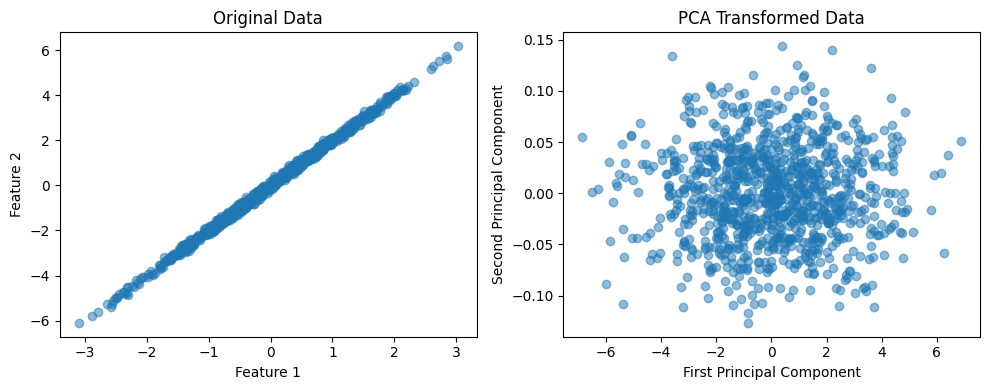

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

class PCA:
    def __init__(self, n_components):
        self.n_components = n_components
        self.components = None
        self.mean = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None
        
    def fit(self, X):
        # Center the data
        self.mean = torch.mean(X, dim=0)
        X = X - self.mean
        
        # Calculate covariance matrix
        cov_matrix = torch.matmul(X.T, X) / (X.shape[0] - 1)
        
        # Calculate eigenvalues and eigenvectors
        eigenvalues, eigenvectors = torch.linalg.eigh(cov_matrix)
        
        # Sort eigenvalues and eigenvectors in descending order
        idx = torch.argsort(eigenvalues, descending=True)
        eigenvalues = eigenvalues[idx]
        eigenvectors = eigenvectors[:, idx]
        
        # Store first n_components eigenvectors
        self.components = eigenvectors[:, :self.n_components]
        
        # Calculate explained variance and ratio
        self.explained_variance_ = eigenvalues[:self.n_components]
        self.explained_variance_ratio_ = eigenvalues[:self.n_components] / torch.sum(eigenvalues)
        
        return self
    
    def transform(self, X):
        # Center the data using stored mean
        X = X - self.mean
        
        # Project data onto principal components
        return torch.matmul(X, self.components)
    
    def inverse_transform(self, X):
        # Project back to original space
        return torch.matmul(X, self.components.T) + self.mean

def main():
    # Generate sample data
    X = torch.randn(1,2,340)
    
    # Create and fit PCA
    pca = PCA(n_components=2)
    pca.fit(X)
    
    # Transform data
    X_transformed = pca.transform(X)
    
    # Print explained variance ratio
    print("Explained variance ratio:", pca.explained_variance_ratio_)
    
    # Visualize original and transformed data
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    
    # Original data
    ax1.scatter(X[:, 0], X[:, 1], alpha=0.5, )
    ax1.set_title('Original Data')
    ax1.set_xlabel('Feature 1')
    ax1.set_ylabel('Feature 2')
    
    # Transformed data
    ax2.scatter(X_transformed[:, 0], X_transformed[:, 1], alpha=0.5)
    ax2.set_title('PCA Transformed Data')
    ax2.set_xlabel('First Principal Component')
    ax2.set_ylabel('Second Principal Component')
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()

## Memory optimization

In [1]:
from models.NKD_linear_layer import *
device='cuda:0' if torch.cuda.is_available() else 'cpu'
dtype = torch.float32
verbose = False

In [74]:
def NLM_torch(input_image, guide_features, window_rad, sigma):
    input_image = input_image.to(dtype)
    guide = guide_features.to(dtype)

    _, _, height, width = input_image.shape
    _, _, l, height, width = guide.shape

    U = torch.zeros_like(input_image, dtype=dtype, device=input_image.device)  # To hold denoised image
    Z = torch.zeros_like(input_image, dtype=dtype, device=input_image.device)  # To hold accumulated weights

    i_str = window_rad
    i_stp = window_rad+height
    j_str = window_rad
    j_stp = window_rad+width

    padded_v = torch.nn.functional.pad(input_image, (window_rad, window_rad, window_rad, window_rad), mode='circular')
    padded_g = torch.nn.functional.pad(guide, (window_rad, window_rad, window_rad, window_rad), mode='constant', value=0)

    normalization_factor = -(sigma * sigma)

    for dx in range(-window_rad, window_rad + 1):
        for dy in range(-window_rad, window_rad + 1):
            print(torch.cuda.memory_allocated(device)/1024**2, 'MB, ', 'start->img2Dshift')
            t = padded_g[:, :, :, i_str+dx:i_stp+dx,j_str+dy:j_stp+dy]
            print(torch.cuda.memory_allocated(device)/1024**2, 'MB, ', 'img2Dshift->diff')
            diff = (guide - t)
            # print(diff.size(0)*diff.size(1)*diff.size(2)*diff.size(3)*diff.size(4)*5/1024**2)
            print(torch.cuda.memory_allocated(device)/1024**2, 'MB, ', 'diff->sqdist')
            sqdist = torch.sum(diff**2, dim=2).to(torch.float64)
            print(torch.cuda.memory_allocated(device)/1024**2, 'MB, ', 'sqdist->hat*exp')
            hat = separable_triangle(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)

            w = hat * torch.exp(sqdist/normalization_factor)
            print(torch.cuda.memory_allocated(device)/1024**2, 'MB, ', 'hat*exp->padded_v')
            v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
            print(torch.cuda.memory_allocated(device)/1024**2, 'MB, ', 'padded_v->Accu_U')
            U = U + w * v
            print(torch.cuda.memory_allocated(device)/1024**2, 'MB, ', 'Accu_U->Accu_Z')
            Z = Z + w
    
    print(torch.cuda.memory_allocated(device)/1024**2, 'MB, ', 'end')

    U = U / Z

    return U.to(dtype)  # U = Denoised image

In [75]:
class NLM_Operator(torch.autograd.Function):
    # Note that forward, setup_context, and backward are @staticmethods
    @staticmethod
    def forward(ctx, input_image, guide_features, window_rad, sigma):
        input_image = input_image.to(torch.float32)
        guide = guide_features.to(torch.float32)

        req_guide_grad = ctx.needs_input_grad[1]
        req_input_grad = ctx.needs_input_grad[0]

        _, _, height, width = input_image.shape
        _, _, l, height, width = guide.shape

        U = torch.zeros_like(input_image, dtype=torch.float64, device=input_image.device)  # To hold denoised image
        Z = torch.zeros_like(input_image, dtype=torch.float64, device=input_image.device)  # To hold accumulated weights
        if req_guide_grad:
            dZ = torch.zeros_like(guide_features, dtype=torch.float64, device=input_image.device)  # To hold accumulated weights

        padded_v = torch.nn.functional.pad(input_image, (window_rad, window_rad, window_rad, window_rad), mode='circular')

        normalization_factor = -(sigma * sigma)

        for dx in range(-window_rad, window_rad + 1):
            for dy in range(-window_rad, window_rad + 1):
                t = img2Dshift(guide, dx, dy)
                diff = (guide - t)
                sqdist = torch.sum(diff**2, dim=2)
                hat = separable_triangle(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)

                w = hat * torch.exp(sqdist/normalization_factor)
                v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
                U = U + w * v
                Z = Z + w
                # print(diff.shape, w.shape, guide_features.shape)
                if req_guide_grad:
                    dZ = dZ + diff * repeat(w, 'b c h w -> b c l h w', l=l)

        U = U / Z

        if req_guide_grad:
            ctx.save_for_backward(input_image, guide, U, Z, dZ, torch.tensor([window_rad], device=input_image.device), torch.tensor([sigma], device=input_image.device))

        return U.to(torch.float32)  # U = Denoised image

    # This function has only a single output, so it gets only one gradient
    @staticmethod
    def backward(ctx, grad_output):
        # This is a pattern that is very convenient - at the top of backward
        # unpack saved_tensors and initialize all gradients w.r.t. inputs to
        # None. Thanks to the fact that additional trailing Nones are
        # ignored, the return statement is simple even when the function has
        # optional inputs.
        input_image, guide, U, Z, dZ, window_rad, sigma = ctx.saved_tensors
        grad_input = None

        _, _, height, width = input_image.shape
        _, _, l, height, width = guide.shape

        # These needs_input_grad checks are optional and there only to
        # improve efficiency. If you want to make your code simpler, you can
        # skip them. Returning gradients for inputs that don't require it is
        # not an error.

        NdLo = grad_output/Z
        grad_guide = torch.zeros_like(guide, dtype=torch.float64, device=input_image.device)  # To hold denoised image

        normalization_factor = -(sigma.item() * sigma.item())

        for dx in range(-window_rad, window_rad + 1):
            for dy in range(-window_rad, window_rad + 1):
                if dx==0 and dy==0:
                    grad_guide = grad_guide - repeat(NdLo * U, 'b c h w -> b c l h w', l=l) * dZ
                    continue
                guide_kl = img2Dshift(guide, dx, dy)
                diff = (guide - guide_kl)
                sqdist = torch.sum(diff**2, dim=2)
                exp = torch.exp(sqdist/normalization_factor)
                input_kl = img2Dshift(input_image, dx, dy)
                NdLo_kl = img2Dshift(NdLo, dx, dy)
                U_kl = img2Dshift(U, dx, dy)
                temp = NdLo_kl * (input_image - U_kl) + NdLo * input_kl
                mask = Box(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)

                grad_guide = grad_guide + mask * (diff * repeat(exp * temp, 'b c h w -> b c l h w', l=l))
        grad_guide = grad_guide * (2 / normalization_factor)
        return grad_input, grad_guide.to(torch.float32), None, None

def NLM(input_image, guide_features, window_rad, sigma):
    return NLM_Operator.apply(input_image, guide_features, window_rad, sigma)

In [76]:
print(torch.cuda.memory_allocated(device)/1024**2)

59.7802734375


In [77]:
# #NKD model
# class NKD_latent_layers_v2(nn.Module):
#     def __init__(self,patch_rad,window_rad,in_channel,latent_dim,latent_channel_dim,device,blind=False,denoiser='NLM'):
#         super().__init__()
#         self.device = device
#         n_heads=4
#         self.n_heads = n_heads
#         self.blind = blind
#         self.L = latent_dim
#         self.l = latent_channel_dim
#         self.sigma = 1
#         self.patch_rad = patch_rad
#         patch_size = patch_rad * 2 + 1

#         self.window_rad = window_rad
#         self.in_channel = in_channel

#         self.in_block = nn.ModuleList([])
#         self.mid_block = nn.ModuleList([])
#         self.norm1 = nn.ModuleList([])
#         self.down1 = nn.ModuleList([])
#         self.norm2 = nn.ModuleList([])
#         self.down2 = nn.ModuleList([])
#         self.norm3 = nn.ModuleList([])
#         self.down3 = nn.ModuleList([])
#         for _ in range(in_channel):
#             if blind:
#                 self.in_block.append(nn.Sequential(
#                     nn.Conv2d(in_channels=in_channel,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
#                     nn.LeakyReLU()
#                 ))
#             else:
#                 self.in_block.append(nn.Sequential(
#                     nn.Conv2d(in_channels=in_channel+1,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
#                     nn.LeakyReLU()
#                 ))
#             self.mid_block.append(nn.Sequential(
#                 nn.Conv2d(latent_dim,latent_dim//2,kernel_size=1,stride=1,padding=0),
#                 nn.LeakyReLU(),
#                 nn.Conv2d(latent_dim//2, latent_dim, kernel_size=1, stride=1, padding=0),
#             ))
#             self.norm1.append(nn.LayerNorm(latent_dim))
#             self.down1.append(nn.Sequential(
#                 nn.Conv2d(latent_dim, latent_dim//2, kernel_size=1, stride=1, padding=0),
#                 nn.LeakyReLU(),
#             ))
#             self.norm2.append(nn.LayerNorm(latent_dim//2))
#             self.down2.append(nn.Sequential(
#                 nn.Conv2d(latent_dim//2, latent_dim//4, kernel_size=1, stride=1, padding=0),
#                 nn.LeakyReLU(),
#             ))
#             self.norm3.append(nn.LayerNorm(latent_dim//4))
#             self.down3.append(nn.Conv2d(latent_dim//4, latent_channel_dim, kernel_size=1, stride=1, padding=0))

#     def forward(self, inp, sig=None):
#         print('input->get_features: ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         guide = self.get_features(inp, sig)
#         print('get_features->NLM: ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         x = NLM(inp, guide, self.window_rad, self.sigma)
#         print('out: ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         return x

#     def get_features(self, guide, sig=None):
#         b, _, h, w = guide.shape
#         pos_emb = get_patch_position_embedding(self.L, (h, w), self.device)
#         for i in range(self.in_channel):
#             print(f'get_features: channel_iter_{i}, ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#             if self.blind:
#                 temp = torch.nn.functional.pad(guide, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
#                 x = self.in_block[i](temp)
#             else:
#                 assert sig!=None, 'In the case of NON-blind model batch std. must be an input'
#                 temp = torch.cat(
#                     (guide, torch.ones((b,1,h,w), device=self.device, dtype=guide.dtype)*sig),
#                     dim=1,
#                 )
#                 temp = torch.nn.functional.pad(temp, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
#                 x = self.in_block[i](temp)

#             print(f'get_features: in_block->res(mid_block), ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#             x = x + pos_emb

#             res = x
#             x = self.mid_block[i](x)
#             x = x + res

#             print(f'get_features: res(mid_block[{i}])->down1[{i}], ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#             # x = torch.functional.F.layer_norm(x)
#             x = self.norm1[i](x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
#             x = self.down1[i](x)
#             print(f'get_features: down1[{i}]->down2[{i}], ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#             x = self.norm2[i](x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
#             x = self.down2[i](x)
#             print(f'get_features: down2[{i}]->down3[{i}], ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#             x = self.norm3[i](x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
#             x = self.down3[i](x)
#             print(f'get_features: down1[{i}]->cat[{i}], ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#             if i==0:
#                 feat = x.unsqueeze(1)
#             else:
#                 feat = torch.cat((feat, x.unsqueeze(1)), dim=1)
#         return feat


# class NKD_latent_layers(nn.Module):
#     def __init__(self, patch_rad, window_rad, in_channel, latent_dim, latent_channel_dim, device, blind=False, denoiser='NLM'):
#         super().__init__()
#         self.device = device
#         n_heads=4
#         self.n_heads = n_heads
#         self.sigma = 1
#         self.blind = blind
#         self.latent_dim = latent_dim
#         self.l = latent_channel_dim
#         self.patch_rad = patch_rad
#         patch_size = patch_rad * 2 + 1

#         self.window_rad = window_rad
#         self.in_channel = in_channel

#         if blind:
#             self.in_block = nn.Sequential(
#                 nn.Conv2d(in_channels=in_channel,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
#                 nn.LeakyReLU()
#             )
#         else:
#             self.in_block = nn.Sequential(
#                 nn.Conv2d(in_channels=in_channel+1,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
#                 nn.LeakyReLU()
#             )

#         self.mid_block = nn.Sequential(
#             nn.Conv2d(latent_dim,latent_dim//2,kernel_size=1,stride=1,padding=0),
#             nn.LeakyReLU(),
#             nn.Conv2d(latent_dim//2, latent_dim, kernel_size=1, stride=1, padding=0),
#         )

#         self.norm1 = nn.LayerNorm(latent_dim)
#         self.down1 = nn.Sequential(
#             nn.Conv2d(latent_dim, latent_dim//2, kernel_size=1, stride=1, padding=0),
#             nn.LeakyReLU(),
#         )

#         self.norm2 = nn.LayerNorm(latent_dim//2)
#         self.down2 = nn.Sequential(
#             nn.Conv2d(latent_dim//2, latent_dim//4, kernel_size=1, stride=1, padding=0),
#             nn.LeakyReLU(),
#         )

#         self.norm3 = nn.LayerNorm(latent_dim//4)
#         self.down3 = nn.Conv2d(latent_dim//4, latent_channel_dim*in_channel, kernel_size=1, stride=1, padding=0)

#     def forward(self, inp, sig=None):
#         print('input->get_features: ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         guide = self.get_features(inp, sig)
#         print('get_features->NLM: ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         x = NLM(inp, guide, self.window_rad, self.sigma)
#         print('out: ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         return x
    
#     def get_features(self, guide, sig=None):
#         b, _, h, w = guide.shape
#         print(f'get_features: channel_iter, ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         if self.blind:
#             temp = torch.nn.functional.pad(guide, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
#             x = self.in_block(temp)
#         else:
#             assert sig!=None, 'In the case of NON-blind model batch std. must be an input'
#             temp = torch.cat(
#                 (guide, torch.ones((b,1,h,w), device=self.device, dtype=guide.dtype)*sig),
#                 dim = 1
#             )
#             temp = torch.nn.functional.pad(temp, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
#             x = self.in_block(temp)

#         print(f'get_features: in_block->res(mid_block), ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         res = x
#         x = self.mid_block(x)
#         x = x + res

#         print(f'get_features: res(mid_block)->down1, ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         x = self.norm1(x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
#         x = self.down1(x)
#         print(f'get_features: down1->down2, ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         x = self.norm2(x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
#         x = self.down2(x)
#         print(f'get_features: down2->down3, ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         x = self.norm3(x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
#         x = self.down3(x)
#         print(f'get_features: down3->rearrange, ',torch.cuda.memory_allocated(device)/1024**2, 'MB')
#         x = rearrange(x, 'b (c l) h w -> b c l h w', l=self.l)

#         return x

In [78]:
# def calculate_tensor_memory(shape, dtype='float32'):
#     """
#     Calculate the memory consumption of a tensor in bytes.
    
#     Parameters:
#     shape (tuple): The shape of the tensor (e.g., (batch_size, height, width, channels))
#     dtype (str): Data type of the tensor elements (default: 'float32')
    
#     Returns:
#     tuple: (bytes, human_readable_size)
#     """
#     # Dictionary of common data type sizes in bytes
#     dtype_sizes = {
#         'float16': 2,
#         'float32': 4,
#         'float64': 8,
#         'int8': 1,
#         'int16': 2,
#         'int32': 4,
#         'int64': 8,
#         'bool': 1,
#         'uint8': 1,
#         'uint16': 2,
#         'uint32': 4,
#         'uint64': 8
#     }
    
#     if dtype not in dtype_sizes:
#         raise ValueError(f"Unsupported dtype: {dtype}")
    
#     # Calculate total number of elements
#     total_elements = 1
#     for dim in shape:
#         total_elements *= dim
    
#     # Calculate total bytes
#     total_bytes = total_elements * dtype_sizes[dtype]
    
#     # Convert to human readable format
#     units = ['B', 'KB', 'MB', 'GB', 'TB']
#     size = float(total_bytes)
#     unit_index = 0
    
#     while size >= 1024.0 and unit_index < len(units) - 1:
#         size /= 1024.0
#         unit_index += 1
    
#     human_readable = f"{size:.2f} {units[unit_index]}"
    
#     return total_bytes, human_readable

# # Example usage
# def print_tensor_info(shape, dtype='float32'):
#     """
#     Print detailed information about tensor memory consumption.
    
#     Parameters:
#     shape (tuple): The shape of the tensor
#     dtype (str): Data type of the tensor elements
#     """
#     total_bytes, human_readable = calculate_tensor_memory(shape, dtype)
#     dimensions = len(shape)
#     elements = 1
#     for dim in shape:
#         elements *= dim
    
#     print(f"Tensor Information:")
#     print(f"Shape: {shape}")
#     print(f"Dimensions: {dimensions}")
#     print(f"Data Type: {dtype}")
#     print(f"Total Elements: {elements:,}")
#     print(f"Memory Usage: {human_readable} ({total_bytes:,} bytes)")

In [79]:
# a = torch.randn(20,3,128,128, requires_grad=False, device=device)

# m = NKD_latent_layers(3, 15, 3, 512, 150, device, True).to(device)
# # m = NKD_latent_layers_v2(3, 15, 3, 512, 128, device, True).to(device)

# b = m(a)
# l = torch.functional.F.mse_loss(a,b)
# l.backward()

In [ ]:
# print(device)
# gt = torch.randn(1,3,64,64, requires_grad=False, device=device)+1
# a = torch.randn(1,3,64,64, requires_grad=False, device=device)+1
# b = torch.randn(1,3,100,64,64, requires_grad=True, device=device)
# print(b.grad)

# # with torch.no_grad():
# # c = b+1
# # c = c.sum(2)
# c = NLM_torch(a, b, 4, 1)
# l = torch.functional.F.mse_loss(c, gt)
# print(l)

# # d = NLM(a, b, 10, 1)
# # l = d.sum()

# l.backward()
# print(b.grad)

# # print((c==d).all())

a = torch.nn.Linear(12,12)
b = torch.randn(32, 12)
c = torch.randn(32, 12)
f = torch.randn(32, 12)

d = a(b)
e = a(c)

g = d+e
l = torch.functional.F.mse_loss(g, f)
l.backward()

print(a.weight.grad)

In [86]:
a.weight.grad

tensor([[ 0.0466, -0.0045,  0.0018,  0.0297,  0.0896,  0.1538, -0.0666, -0.0454,
         -0.0151, -0.0364,  0.0488,  0.0108],
        [-0.0341,  0.0275,  0.0805,  0.1817, -0.0302,  0.0903,  0.1523,  0.0522,
          0.1475, -0.0887, -0.0340,  0.0266],
        [-0.1971,  0.0095,  0.0413,  0.0557, -0.1217, -0.1663,  0.0802,  0.0599,
         -0.0440, -0.0727, -0.1281, -0.0951],
        [ 0.0233,  0.0619,  0.1088, -0.1195,  0.0098,  0.0185, -0.0346, -0.0201,
         -0.0006,  0.0734,  0.0015, -0.0521],
        [ 0.0040,  0.0090,  0.0238,  0.0110, -0.0521, -0.0248, -0.0271,  0.0196,
          0.0023,  0.1019, -0.0535, -0.0374],
        [ 0.0841, -0.0127,  0.1106, -0.0691, -0.0792,  0.0191,  0.0242, -0.0686,
          0.0167, -0.0244,  0.1030, -0.0020],
        [-0.0475, -0.0173,  0.1963,  0.0046,  0.0653,  0.0980,  0.0384,  0.0714,
          0.0043,  0.0135, -0.0784,  0.0621],
        [ 0.0535,  0.0472,  0.0105, -0.0467, -0.0439, -0.0151,  0.0248, -0.0966,
          0.0085,  0.0467, -0.

In [11]:
b.grad.max()

tensor(0., device='cuda:0')

In [ ]:
from einops import rearrange

In [34]:
channels = 3
m, n = 4, 4
l=5
w = 7
a = torch.randn(1,channels,l,m,n, requires_grad=False, device=device)
_,_,_,m,n = a.shape
a1 = torch.functional.F.pad(a, (w, w, w, w), mode='constant', value=0)



In [42]:
b = torch.randn(1,3,4,4, requires_grad=False, device=device)

dx = -1
dy = -1

t = img2Dshift(a, dx, dy)
t1 = a1[:, :, :, w+dx:w+dx+m,w+dy:w+dy+n]

diff = (a - t)
diff1 = (a - t1)

sqdist = torch.sum(diff**2, dim=2)
sqdist1 = torch.sum(diff1**2, dim=2)

for dx in range(-w, w + 1):
    for dy in range(-w, w + 1):
        t = a1[:, :, :, w+dx:w+dx+m,w+dy:w+dy+n]

# print((sqdist1==sqdist).all())

tensor(True, device='cuda:0')


In [16]:
# for dx in range(-window_rad, window_rad + 1):
#     for dy in range(-window_rad, window_rad + 1):
#                 t = img2Dshift(guide, dx, dy)
#                 diff = (guide - t)
#                 sqdist = torch.sum(diff**2, dim=2)
#                 hat = separable_triangle(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)

#                 w = hat * torch.exp(sqdist/normalization_factor)
#                 v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
#                 U = U + w * v
#                 Z = Z + w
#                 # print(diff.shape, w.shape, guide_features.shape)
#                 if req_guide_grad:
#                     dZ = dZ + diff * repeat(w, 'b c h w -> b c l h w', l=l)

tensor([[[[ 4.7673e-01,  3.8554e-02,  2.9677e-01,  ..., -1.0129e+00,
            8.3853e-01, -1.2394e+00],
          [ 5.5717e-01, -1.2234e+00, -2.1290e-01,  ..., -2.8640e-01,
           -2.1155e+00,  1.7290e+00],
          [ 7.0344e-01, -1.1595e+00, -5.4134e-01,  ...,  2.1810e+00,
            6.9733e-01, -1.4841e+00],
          ...,
          [ 9.1910e-01, -1.6031e-02, -6.9216e-01,  ..., -2.2268e-01,
           -4.1957e-01,  6.6415e-01],
          [ 6.9530e-01, -1.8426e-01, -5.8741e-01,  ..., -8.3731e-02,
           -7.1166e-01,  4.2692e-01],
          [ 2.8907e-01, -5.5773e-01,  3.0995e+00,  ..., -8.0186e-02,
           -3.6519e-01, -2.2962e+00]],

         [[-1.8952e+00,  1.0629e+00, -1.8481e+00,  ..., -6.2539e-02,
           -4.4447e-01,  1.0583e+00],
          [-3.4769e-01, -7.0494e-01,  4.2450e-01,  ..., -3.1335e-01,
            3.9974e-01, -6.0508e-01],
          [-6.0940e-01, -8.5345e-01,  2.7201e-01,  ..., -1.1305e+00,
            1.1851e+00,  4.0877e-01],
          ...,
     

## DSG-NML

In [1]:
def show_tensor_image(image_tensors : list, grid : tuple, titles=None, save=False, save_path=None):
    x, y = grid
    _, axs = plt.subplots(x, y, figsize=(5*y, 5*x))
    # Convert tensors to numpy arrays for plotting
    if not isinstance(image_tensors, list):
        image_tensors = [image_tensors]
    if titles is not None:
        if not isinstance(titles, list):
            titles = [titles]
        assert len(image_tensors) == len(titles), 'Number of images and titles must be the same.'

    for i in range(x):
        for j in range(y):
            index = i*y + j
            if index >= len(image_tensors):
                break
            np_image = image_tensors[index].squeeze(0).detach().cpu().numpy().transpose(1, 2, 0)
            if y>1 and x>1:
                axs[i,j].imshow(np_image)
                if titles:
                    axs[i,j].set_title(titles[index])
                axs[i,j].axis('off')

            elif y>1:
                axs[j].imshow(np_image)
                if titles:
                    axs[j].set_title(titles[index])
                axs[j].axis('off')

            elif x>1:
                axs[i].imshow(np_image)
                if titles:
                    axs[i].set_title(titles[index])
                axs[i].axis('off')
            else:
                plt.imshow(np_image)
                if titles:
                    plt.set_title(titles[index])
                plt.axis('off')

    plt.tight_layout()
    if save: plt.savefig(save_path)
    else: plt.show()


In [6]:
from denoisers.NLM_torch import integral_img_sq_diff, separable_triangle, img2Dshift, torch

def DSG_NLM(input_image,guide_image,patch_rad,window_rad,sigma):
    #convert input_image to double
    input_image = input_image.to(torch.float32)
    guide_image = guide_image.to(torch.float32)

    b,channel,height,width = input_image.shape
    u = torch.zeros((b, channel, height, width)).to(torch.float64)
    
    u = torch.zeros((b, channel, height, width), dtype=torch.float32, device=input_image.device)  # To hold denoised image
    W0 = torch.zeros((b, channel, height, width), dtype=torch.float32, device=input_image.device)  # To hold accumulated weights

    guide = torch.nn.functional.pad(guide_image, (patch_rad, patch_rad, patch_rad, patch_rad), mode='circular')
    padded_v = torch.nn.functional.pad(input_image, (window_rad, window_rad, window_rad, window_rad), mode='circular')

    normalization_factor = -(sigma*sigma)

    # 0th loop
    W0 = torch.zeros((b,channel,height,width)).to(device=input_image.device, dtype=torch.float64)
    for dx in range(-window_rad,window_rad+1):
        for dy in range(-window_rad,window_rad+1):
            t = img2Dshift(guide, dx, dy)
            diff = (guide - t)
            sqdist = torch.sum(diff**2, dim=2)
            hat = separable_triangle(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)
            w = hat * torch.exp(sqdist/normalization_factor)

            W0 = W0 + w

    # 1st loop
    W1 = torch.zeros((b,channel,height,width)).to(device=input_image.device, dtype=torch.float64)
    for dx in range(-window_rad,window_rad+1):
        for dy in range(-window_rad,window_rad+1):
            t = img2Dshift(guide, dx, dy)
            diff = (guide - t)
            sqdist = torch.sum(diff**2, dim=2)
            hat = separable_triangle(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)
            w = hat * torch.exp(sqdist/normalization_factor)

            W0_pad = torch.nn.functional.pad(W0,(window_rad, window_rad, window_rad, window_rad),mode='circular')
            W0_shift = img2Dshift(W0_pad,dx,dy)
            W0_temp = W0_shift[:, :, window_rad:window_rad+height,window_rad:window_rad+width]
            w1 = w / (torch.sqrt(W0)*torch.sqrt(W0_temp)).to(torch.float64)
            W1 = W1 + w1
    
    # 2nd loop
    alpha = 1/torch.max(W1).to(torch.float64)
    W2 = torch.zeros((b,channel,height,width)).to(device=input_image.device, dtype=torch.float64)
    for dx in range(-window_rad,window_rad+1):
        for dy in range(-window_rad,window_rad+1):
            if((dx != 0) or (dy != 0)):
                t = img2Dshift(guide, dx, dy)
                diff = (guide - t)
                sqdist = torch.sum(diff**2, dim=2)
                hat = separable_triangle(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)
                w = hat * torch.exp(sqdist/normalization_factor)

                W0_pad = torch.nn.functional.pad(W0,(window_rad, window_rad, window_rad, window_rad),mode='circular')
                W0_shift = img2Dshift(W0_pad,dx,dy)
                W0_temp = W0_shift[:, :, window_rad:window_rad+height,window_rad:window_rad+width]
                w2 = (alpha*w) / (torch.sqrt(W0)*torch.sqrt(W0_temp)).to(torch.float64)
                v = padded_v[:, :, window_rad+dx:window_rad+dx+height,window_rad+dy:window_rad+dy+width]
                u = u + w2*v
                W2 = W2 + w2

    u = u + (1-W2)*input_image
    #convert u to double
    u = u.to(torch.float64)
    return u        # u = Denoised image

######################################################################################
######################################################################################
#------------------              DSG NLM FAST ENDS         ----------------------------



Loading testing images...
Loaded 2 images from curr_test
Total loaded 2 images from: curr_test
Loaded 2 images for testing


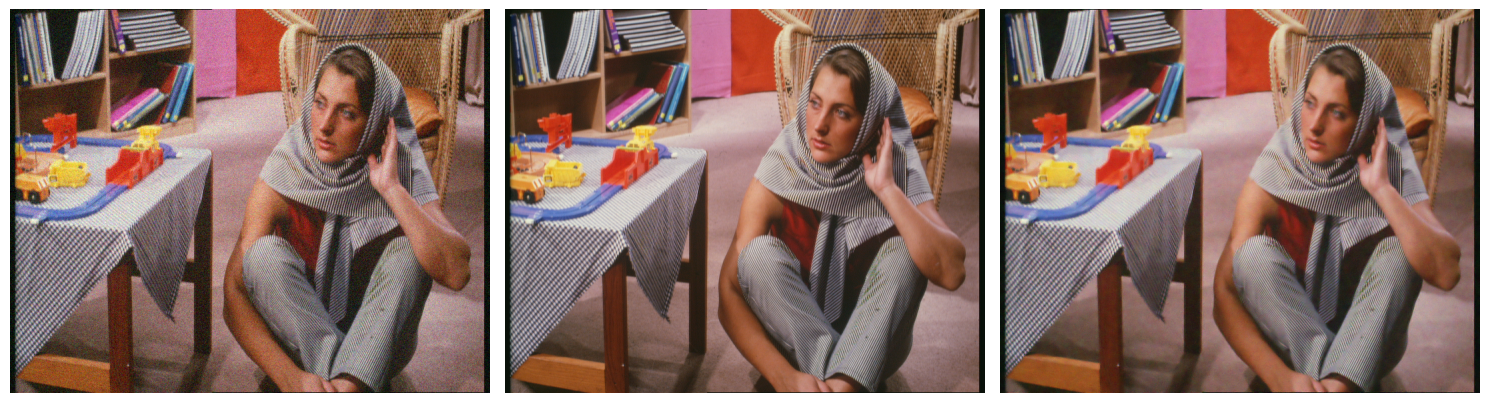

tensor(0.9874, device='cuda:0', dtype=torch.float64)


In [7]:
from dataset_loaders import TestDataset, DataLoader
# from denoisers.NLM_torch import NLM_tensor
import torch
import matplotlib.pyplot as plt

device='cuda:0' if torch.cuda.is_available() else 'cpu'

testset = TestDataset('./data/show', 'rgb', 15, show=True)

test_loader = DataLoader(
            testset,
            batch_size=1,  # Process one full image at a time
            shuffle=False,
            pin_memory=True
        )

for i, data in enumerate(test_loader):
    # fig, axes = plt.subplots(len(name), 3, figsize=(15, 5 * len(name)))

    clean_image, noisy_image, sigma = data  # dataset returns a tuple of (noisy_image, clean_image)

    # Move images to the same device as the model
    noisy_image = noisy_image.to(device=device, dtype=torch.float64)
    clean_image = clean_image.to(device=device, dtype=torch.float64)
    # noisy_image = noisy_image.squeeze().detach().cpu().numpy().transpose(1,2,0)
    # clean_image = clean_image.squeeze().detach().cpu().numpy().transpose(1,2,0)
    # sigma = sigma.squeeze().detach().cpu().numpy().transpose(1,2,0)

    a = DSG_NLM(noisy_image, noisy_image, 3, 5, 0.6)

    # plt.imshow(a, cmap='gray')
    # plt.show()
    show_tensor_image([noisy_image, clean_image, a], (1,3))

    print(a.max())
    
    break

    
    



Loading testing images...
Loaded 2 images from curr_test
Total loaded 2 images from: curr_test
Loaded 2 images for testing


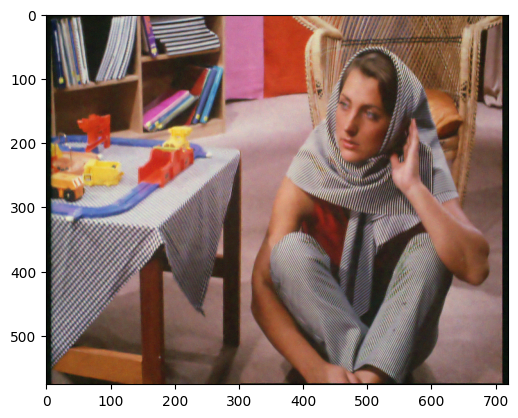

tensor(0.9884, device='cuda:0', dtype=torch.float64)


In [4]:
from dataset_loaders import TestDataset, DataLoader
from denoisers.NLM import DSG_NLM
import torch
import matplotlib.pyplot as plt

device='cuda:0' if torch.cuda.is_available() else 'cpu'

testset = TestDataset('./data/show', 'rgb', 15, show=True)

test_loader = DataLoader(
            testset,
            batch_size=1,  # Process one full image at a time
            shuffle=False,
            pin_memory=True
        )

for i, data in enumerate(test_loader):

    clean_image, noisy_image, sigma = data  
    
    noisy_image = noisy_image.squeeze().detach().cpu().numpy().transpose(1,2,0)
    clean_image = clean_image.squeeze().detach().cpu().numpy().transpose(1,2,0)
    out = np.zeros_like(noisy_image)

    for i in range(3):
        out[:, :, i] = DSG_NLM(noisy_image[:, :, i], noisy_image[:, :, i], 3, 5, 0.6)

    plt.imshow(out, cmap='gray')
    plt.show()

    print(a.max())
    
    break

In [23]:
a.max()

tensor(nan, device='cuda:0', dtype=torch.float64)

## NLM OPERATOR

In [1]:
from models.NKD_linear_layer import *
from dataset_loaders import TrainingDataset, DataLoader

torch.manual_seed(100)
np.random.seed(100)

device='cuda:0' if torch.cuda.is_available() else 'cpu'
print(device)


cuda:0


In [2]:

def img2Dshift(v, dx, dy):
    typ = (1 if dx > 0 else 0) * 2 + (1 if dy > 0 else 0)
    if len(v.shape) == 4:
        batch, c, row, col = v.shape
        t = torch.zeros((batch, c, row, col), device=v.device, dtype=v.dtype)

        if typ == 0:  # dx <= 0, dy <= 0
            t[:,:,-dx:, -dy:] = v[:,:,:row + dx, :col + dy]
        elif typ == 1:  # dx <= 0, dy > 0
            t[:,:,-dx:, :col - dy] = v[:,:,:row + dx, dy:]
        elif typ == 2:  # dx > 0, dy <= 0
            t[:,:,:row - dx, -dy:] = v[:,:,dx:, :col + dy]
        elif typ == 3:  # dx > 0, dy > 0
            t[:,:,:row - dx, :col - dy] = v[:,:,dx:, dy:]
    elif len(v.shape) == 5:
        batch, n, c, row, col = v.shape
        t = torch.zeros((batch, n, c, row, col), device=v.device, dtype=v.dtype)

        if typ == 0:  # dx <= 0, dy <= 0
            t[:,:,:,-dx:, -dy:] = v[:,:,:,:row + dx, :col + dy]
        elif typ == 1:  # dx <= 0, dy > 0
            t[:,:,:,-dx:, :col - dy] = v[:,:,:,:row + dx, dy:]
        elif typ == 2:  # dx > 0, dy <= 0
            t[:,:,:,:row - dx, -dy:] = v[:,:,:,dx:, :col + dy]
        elif typ == 3:  # dx > 0, dy > 0
            t[:,:,:,:row - dx, :col - dy] = v[:,:,:,dx:, dy:]
    else:
        batch, row, col = v.shape
        t = torch.zeros((batch, row, col), device=v.device, dtype=v.dtype)

        if typ == 0:  # dx <= 0, dy <= 0
            t[:,-dx:, -dy:] = v[:,:row + dx, :col + dy]
        elif typ == 1:  # dx <= 0, dy > 0
            t[:,-dx:, :col - dy] = v[:,:row + dx, dy:]
        elif typ == 2:  # dx > 0, dy <= 0
            t[:,:row - dx, -dy:] = v[:,dx:, :col + dy]
        elif typ == 3:  # dx > 0, dy > 0
            t[:,:row - dx, :col - dy] = v[:,dx:, dy:]
    return t


def separable_triangle(dx, dy, Ns, height, width):

    # Calculate the value from dx, dy, and Ns
    # value = max(0, 1 - (abs(dx) / (Ns + 1))) * max(0, 1 - (abs(dy) / (Ns + 1)))
    value = 1

    # Build the 2D array Hat with all values equal to `value`
    Hat = torch.full((height, width), value, dtype=torch.float32)

    # Adjust pixel values to zero where the destination pixel is outside the image
    if dx >= 0:
        Hat[height - dx:, :] = 0
    else:
        Hat[:abs(dx), :] = 0

    if dy >= 0:
        Hat[:, width - dy:] = 0
    else:
        Hat[:, :abs(dy)] = 0

    return Hat


In [3]:
#nlm_op
# Inherit from Function
class NLM_Operator(torch.autograd.Function):
    # Note that forward, setup_context, and backward are @staticmethods
    @staticmethod
    def forward(ctx, input_image, guide_features, window_rad, sigma):
        input_image = input_image.to(torch.float32)
        guide = guide_features.to(torch.float32)

        req_guide_grad = ctx.needs_input_grad[1]
        req_input_grad = ctx.needs_input_grad[0]

        _, _, height, width = input_image.shape
        _, _, l, height, width = guide.shape

        U = torch.zeros_like(input_image, dtype=torch.float64, device=input_image.device)  # To hold denoised image
        Z = torch.zeros_like(input_image, dtype=torch.float64, device=input_image.device)  # To hold accumulated weights
        if req_guide_grad:
            dZ = torch.zeros_like(guide_features, dtype=torch.float64, device=input_image.device)  # To hold accumulated weights

        padded_v = torch.nn.functional.pad(input_image, (window_rad, window_rad, window_rad, window_rad), mode='circular')

        normalization_factor = -(sigma * sigma)

        for dx in range(-window_rad, window_rad + 1):
            for dy in range(-window_rad, window_rad + 1):
                t = img2Dshift(guide, dx, dy)
                diff = (guide - t)
                sqdist = torch.sum(diff**2, dim=2)
                hat = separable_triangle(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)

                w = hat * torch.exp(sqdist/normalization_factor)
                v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
                U = U + w * v
                Z = Z + w
                # print(diff.shape, w.shape, guide_features.shape)
                if req_guide_grad:
                    dZ = dZ + diff * repeat(w, 'b c h w -> b c l h w', l=l)

        U = U / Z

        if req_guide_grad:
            ctx.save_for_backward(input_image, guide, U, Z, dZ, torch.tensor([window_rad], device=input_image.device), torch.tensor([sigma], device=input_image.device))

        return U.to(torch.float32)  # U = Denoised image

    # This function has only a single output, so it gets only one gradient 
    @staticmethod
    def backward(ctx, grad_output):
        # This is a pattern that is very convenient - at the top of backward 
        # unpack saved_tensors and initialize all gradients w.r.t. inputs to 
        # None. Thanks to the fact that additional trailing Nones are
        # ignored, the return statement is simple even when the function has
        # optional inputs.
        input_image, guide, U, Z, dZ, window_rad, sigma = ctx.saved_tensors
        grad_input = None

        _, _, height, width = input_image.shape
        _, _, l, height, width = guide.shape

        # These needs_input_grad checks are optional and there only to
        # improve efficiency. If you want to make your code simpler, you can
        # skip them. Returning gradients for inputs that don't require it is
        # not an error.

        NdLo = grad_output/Z
        grad_guide = torch.zeros_like(guide, dtype=torch.float64, device=input_image.device)  # To hold denoised image

        normalization_factor = -(sigma.item() * sigma.item())

        for dx in range(-window_rad, window_rad + 1):
            for dy in range(-window_rad, window_rad + 1):
                if dx==0 and dy==0:
                    grad_guide = grad_guide - repeat(NdLo * U, 'b c h w -> b c l h w', l=l) * dZ
                    continue
                guide_kl = img2Dshift(guide, dx, dy)
                diff = (guide - guide_kl)
                sqdist = torch.sum(diff**2, dim=2)
                exp = torch.exp(sqdist/normalization_factor)
                input_kl = img2Dshift(input_image, dx, dy)
                NdLo_kl = img2Dshift(NdLo, dx, dy)
                U_kl = img2Dshift(U, dx, dy)
                temp = NdLo_kl * (input_image - U_kl) + NdLo * input_kl
                mask = Box(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)

                grad_guide = grad_guide + mask * (diff * repeat(exp * temp, 'b c h w -> b c l h w', l=l))
        grad_guide = grad_guide * (2 / normalization_factor)
        return grad_input, grad_guide, None, None

def NLM(input_image, guide_features, window_rad, sigma):
        input_image = input_image.to(torch.float32)
        guide = guide_features.to(torch.float32)

        _, _, height, width = input_image.shape

        U = torch.zeros_like(input_image, dtype=torch.float64, device=input_image.device)  # To hold denoised image
        Z = torch.zeros_like(input_image, dtype=torch.float64, device=input_image.device)  # To hold accumulated weights

        padded_v = torch.nn.functional.pad(input_image, (window_rad, window_rad, window_rad, window_rad), mode='circular')

        normalization_factor = -(sigma * sigma)

        for dx in range(-window_rad, window_rad + 1):
            for dy in range(-window_rad, window_rad + 1):
                t = img2Dshift(guide, dx, dy)
                diff = (guide - t)
                sqdist = torch.sum(diff**2, dim=2)
                hat = separable_triangle(dx, dy, window_rad, height, width).to(device=input_image.device, dtype = torch.float64)

                w = hat * torch.exp(sqdist/normalization_factor)
                v = padded_v[:, :, window_rad + dx:window_rad + dx + height, window_rad + dy:window_rad + dy + width]
                U = U + w * v
                Z = Z + w

        U = U / Z

        return U.to(torch.float32)  # U = Denoised image

# device='cuda:0' if torch.cuda.is_available() else 'cpu'


In [4]:
class NKD_latent_layers(nn.Module):
    def __init__(self,patch_rad,window_rad,in_channel,latent_dim,latent_channel_dim,device,blind=False,denoiser='NLM'):
        super().__init__()
        self.device = device
        n_heads=4
        self.n_head = n_heads
        self.blind = blind
        self.l = latent_channel_dim
        self.patch_rad = patch_rad
        patch_size = patch_rad * 2 + 1

        self.window_rad = window_rad
        self.in_channel = in_channel

        if blind:
            self.in_block = nn.Sequential(
                nn.Conv2d(in_channels=in_channel,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
                nn.LeakyReLU()
            )
        else:
            self.in_block = nn.Sequential(
                nn.Conv2d(in_channels=in_channel+1,out_channels=latent_dim,kernel_size=patch_size,stride=1,padding=0),
                nn.LeakyReLU()
            )

        self.mid_block = nn.Sequential(
            nn.Conv2d(latent_dim,latent_dim//2,kernel_size=1,stride=1,padding=0),
            nn.LeakyReLU(),
            nn.Conv2d(latent_dim//2, latent_dim, kernel_size=1, stride=1, padding=0),
        )

        self.norm1 = nn.LayerNorm(latent_dim)
        self.down1 = nn.Sequential(
            nn.Conv2d(latent_dim, latent_dim//2, kernel_size=1, stride=1, padding=0),
            nn.LeakyReLU(),
        )

        self.norm2 = nn.LayerNorm(latent_dim//2)
        self.down2 = nn.Sequential(
            nn.Conv2d(latent_dim//2, latent_dim//4, kernel_size=1, stride=1, padding=0),
            nn.LeakyReLU(),
        )

        self.norm3 = nn.LayerNorm(latent_dim//4)
        self.down3 = nn.Conv2d(latent_dim//4, latent_channel_dim*in_channel, kernel_size=1, stride=1, padding=0)

        self.sigma = 1

    def forward(self, inp, sig=None, op='nlm_imp'):
        if self.blind:
            temp = torch.nn.functional.pad(inp, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
            x = self.in_block(temp)
        else:
            assert sig!=None, 'In the case of NON-blind model batch std. must be an input'
            temp = torch.nn.functional.pad(inp, (self.patch_rad, self.patch_rad, self.patch_rad, self.patch_rad), mode='circular')
            b, _, h, w = temp.shape
            temp = torch.cat(
                (temp, torch.ones((b,1,h,w), device=self.device, dtype=inp.dtype)*sig),
                dim=1
            )
            x = self.in_block(temp)

        res = x
        x = self.mid_block(x)
        x = x + res

        x = self.norm1(x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
        x = self.down1(x)
        x = self.norm2(x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
        x = self.down2(x)
        x = self.norm3(x.permute(0,3,2,1).contiguous()).permute(0,3,2,1).contiguous()
        x = self.down3(x)
        x = rearrange(x, 'b (c l) h w -> b c l h w', l=self.l)

        if op == 'nlm_imp':
            x = NLM_Operator.apply(inp, x, self.window_rad, self.sigma)
        else:
            x = NLM(inp, x, self.window_rad, self.sigma)
        return x
    
    def train_step(self, op, train_loader, criterion, optimizer, lamda = 1e-3):
        self.train()
        loss = 0

        for clean, noisy, sigma in train_loader:
            clean = clean.to(self.device, dtype=torch.float32)
            noisy = noisy.to(self.device, dtype=torch.float32)
            sigma = sigma.to(self.device, dtype=torch.float32)
            b = clean.size(0)

            # More efficient than zero_grad()
            optimizer.zero_grad(set_to_none=True)

            output = self(noisy, sigma, op=op)

            if lamda!=0:
                l1 = l1_loss(self)
            else:
                l1 = 0
                
            loss = criterion(output, clean)
            loss_t = loss + lamda*l1
            loss_t.backward()
            optimizer.step()

            loss = (loss.item() * b)

        loss = loss/len(train_loader.dataset)
        return loss
    

In [5]:
model = NKD_latent_layers(3, 4, 3, 512, 10, device).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
criterion = torch.nn.MSELoss()

testset = TrainingDataset('./data/train', 'rgb', 15, 15)

train_loader = DataLoader(
    testset,
    batch_size=10,  # Process one full image at a time
    shuffle=False,
    pin_memory=True
)



Loading training images...
Loaded 400 images from BSD400
Total loaded 400 images from: BSD400
Loaded 400 images for training


In [6]:

model.train()
for epoch in range(10):
    batch_count = 0
    current_lr = optimizer.param_groups[0]['lr']

    loss = model.train_step('nlm_imp_', train_loader, criterion, optimizer, lamda=0.0)
    print(loss)

6.545298674609512e-05
4.9211987061426044e-05
4.9392601795261726e-05
2.3792585125193e-05
4.044484376208857e-05
4.813493796973489e-05
5.500547922565602e-05
5.261407932266593e-05
2.6869693101616576e-05
3.335881410748698e-05


In [ ]:

model.train()
for epoch in range(10):
    batch_count = 0
    current_lr = optimizer.param_groups[0]['lr']

    loss = model.train_step('nlm_imp', train_loader, criterion, optimizer, lamda=0.0)
    print(loss)

6.546719669131562e-05
4.923748565488495e-05
4.9425299948779866e-05
2.3799268092261627e-05
4.04042839363683e-05
4.815950887859799e-05
5.500565021065995e-05
5.25935429322999e-05
2.6983878342434764e-05
3.3409465686418116e-05


In [6]:

# import time
# # input_tensor = torch.randn((20, 3, 128, 128), device=nkd_linear_layer.device)

# input_tensor = torch.randn((1, 3, 128, 128), device=device, requires_grad=False)
# guide_tensor = torch.randn((1, 3, 10, 128, 128), device=device, requires_grad=True)

# t1 = time.time()
# # out = NLM(input_tensor, guide_tensor, 10, 1)
# out = NLM_Operator.apply(input_tensor, guide_tensor, 10, 1)
# out = torch.functional.F.mse_loss(out,input_tensor)
# out.backward()
# torch.cuda.synchronize()
# print('calculation time using pytorch autograd: ', time.time()-t1, 'seconds')
# a = guide_tensor.grad

# print(input_tensor, a)


calculation time using pytorch autograd:  1.1140203475952148 seconds
tensor([[[[ 0.5262,  0.4127,  1.0971,  ..., -0.4991, -0.0579,  0.1637],
          [ 1.8492,  1.0140, -0.6577,  ..., -0.2570,  0.0623, -0.2698],
          [-0.5718, -0.9177,  0.1337,  ...,  1.3144, -0.4196,  0.5098],
          ...,
          [ 0.3990,  1.1749, -0.1783,  ...,  0.6064, -1.5993, -0.0762],
          [ 2.1059, -0.2608, -0.2095,  ..., -1.6368, -0.2072, -0.7176],
          [ 0.3438,  0.3215,  1.1420,  ...,  1.5890,  0.0684, -0.2820]],

         [[ 0.1594, -1.1075,  1.0625,  ...,  1.2368,  1.6631,  0.5353],
          [-0.8710, -1.0219,  1.4086,  ..., -1.2043,  1.0531,  0.4214],
          [ 0.0528,  0.8664,  0.4864,  ..., -1.6115,  1.2090, -0.7366],
          ...,
          [ 0.2537, -0.0427, -0.2540,  ..., -0.6999, -0.5526, -0.9796],
          [ 0.3375, -1.6012,  1.3136,  ..., -0.9322, -0.6456,  1.2860],
          [ 0.0607,  0.6165, -0.6322,  ...,  0.7881,  1.4385, -0.8346]],

         [[-1.8374, -0.5668,  1.2

In [ ]:

# import time
# input_tensor = torch.randn((1, 3, 128, 128), device=device, requires_grad=False)
# guide_tensor = torch.randn((1, 3, 10, 128, 128), device=device, requires_grad=True)

# t1 = time.time()
# out = NLM(input_tensor, guide_tensor, 10, 1)
# # out = NLM_Operator.apply(input_tensor, guide_tensor, 10, 1)
# out = torch.functional.F.mse_loss(out,input_tensor)
# out.backward()
# torch.cuda.synchronize()
# print('calculation time using pytorch autograd: ', time.time()-t1, 'seconds')
# a = guide_tensor.grad

# print(input_tensor, a)

calculation time using pytorch autograd:  0.4347801208496094 seconds
tensor([[[[ 0.5262,  0.4127,  1.0971,  ..., -0.4991, -0.0579,  0.1637],
          [ 1.8492,  1.0140, -0.6577,  ..., -0.2570,  0.0623, -0.2698],
          [-0.5718, -0.9177,  0.1337,  ...,  1.3144, -0.4196,  0.5098],
          ...,
          [ 0.3990,  1.1749, -0.1783,  ...,  0.6064, -1.5993, -0.0762],
          [ 2.1059, -0.2608, -0.2095,  ..., -1.6368, -0.2072, -0.7176],
          [ 0.3438,  0.3215,  1.1420,  ...,  1.5890,  0.0684, -0.2820]],

         [[ 0.1594, -1.1075,  1.0625,  ...,  1.2368,  1.6631,  0.5353],
          [-0.8710, -1.0219,  1.4086,  ..., -1.2043,  1.0531,  0.4214],
          [ 0.0528,  0.8664,  0.4864,  ..., -1.6115,  1.2090, -0.7366],
          ...,
          [ 0.2537, -0.0427, -0.2540,  ..., -0.6999, -0.5526, -0.9796],
          [ 0.3375, -1.6012,  1.3136,  ..., -0.9322, -0.6456,  1.2860],
          [ 0.0607,  0.6165, -0.6322,  ...,  0.7881,  1.4385, -0.8346]],

         [[-1.8374, -0.5668,  1.2

## POSITIONAL EMBEDDING

In [8]:
from einops import repeat

input_tensor = torch.randn((20, 3, 128, 128), device='cpu', requires_grad=False)
guide_tensor = torch.randn((20, 3, 10, 128, 128), device='cpu', requires_grad=True)

print((repeat(input_tensor, 'b c h w -> b c l h w', l=10)*guide_tensor).shape)

torch.Size([20, 3, 10, 128, 128])


In [40]:
import torch
from einops import rearrange


def get_position_embedding(pos_emb_dim, grid_size, device):
    assert pos_emb_dim % 4 == 0, 'Position embedding dimension must be divisible by 4'
    grid_size_h, grid_size_w = grid_size
    grid_h = torch.arange(grid_size_h, dtype=torch.float32, device=device)
    grid_w = torch.arange(grid_size_w, dtype=torch.float32, device=device)
    grid = torch.meshgrid(grid_h, grid_w, indexing='ij')
    grid = torch.stack(grid, dim=0)

    # grid_h_positions -> (Number of patch tokens,)
    grid_h_positions = grid[0].reshape(-1)
    grid_w_positions = grid[1].reshape(-1)

    # factor = 10000^(2i/d_model)
    factor = 10000 ** ((torch.arange(
        start=0,
        end=pos_emb_dim // 4,
        dtype=torch.float32,
        device=device) / (pos_emb_dim // 4))
    )

    grid_h_emb = grid_h_positions[:, None].repeat(1, pos_emb_dim // 4) / factor
    grid_h_emb = torch.cat([torch.sin(grid_h_emb), torch.cos(grid_h_emb)],dim=-1)
    # grid_h_emb -> (Number of patch tokens, pos_emb_dim // 2)

    grid_w_emb = grid_w_positions[:, None].repeat(1, pos_emb_dim // 4) / factor
    grid_w_emb = torch.cat([torch.sin(grid_w_emb), torch.cos(grid_w_emb)],dim=-1)
    # grid_w_emb -> (Number of patch tokens, pos_emb_dim // 2)

    pos_emb = torch.cat([grid_h_emb, grid_w_emb], dim=-1)
    # pos_emb -> (Number of patch tokens, pos_emb_dim)

    return pos_emb

h,w = 124,32

positional_emb1 = rearrange(get_patch_position_embedding(512, (h, w), 'cpu'),'(h w) d -> 1 d h w', h = h)
positional_emb = get_patch_position_embedding(512, (h, w), 'cpu')

In [41]:
for i in range(h):
    for j in range(w):
        assert (positional_emb1[:, :, i, j]==positional_emb[i*w+j, :]).all().item()

In [32]:
a = torch.randn((10, 512, 128, 128))
b = a + positional_emb1

# Pnp

In [2]:
# from models.NKD_linear_layer import NLM
# import torch

# def load_denoiser(architecture, checkpoint, device):

#     states = torch.load(checkpoint, weights_only=False)
#     denoiser = architecture(
#         patch_rad=states['args'].patch_rad, 
#         window_rad=states['args'].window_rad,
#         in_channel=states['args'].in_channel,
#         latent_dim=states['args'].latent_dim,
#         latent_channel_dim=states['args'].latent_channel_dim,
#         device=device,
#         blind=states['args'].blind,
#     )
#     denoiser.load_state_dict(states['model_state_dict'])
#     print('Denoiser specifications:')
#     print('patch_rad=',states['args'].patch_rad)
#     print('window_rad=',states['args'].window_rad)
#     print('in_channel=',states['args'].in_channel)
#     print('latent_dim=',states['args'].latent_dim)
#     print('latent_channel_dim=',states['args'].latent_channel_dim)
#     print('blind=',states['args'].blind)

#     return denoiser

# class NKD_regularizer:
#     def __init__(self, architecture, checkpoint, device):
#         """
#         Initializes the class with the given architecture, checkpoint, and device.
#         Args:
#             architecture (class): The architecture type for the denoiser.
#             checkpoint (str): The path to the checkpoint file for loading the denoiser.
#             device (str): The device to run the denoiser on (e.g., 'cpu' or 'cuda').
#         Attributes:
#             denoiser: The loaded denoiser model.
#             device (str): The device to run the denoiser on.
#         """
        
#         self.denoiser = load_denoiser(architecture, checkpoint, device)
#         self.device = device

#     def __call__(self, noisy_input, guide):
#         feat = self.denoiser.get_features(guide)
#         out = NLM(noisy_input, feat, self.denoiser.window_rad, self.denoiser.sigma)
#         return out

In [3]:
# def show_tensor_image(image_tensors : list, grid : tuple, titles=None, save=False, save_path=None):
#     x, y = grid
#     _, axs = plt.subplots(x, y, figsize=(5*y, 5*x))
#     # Convert tensors to numpy arrays for plotting
#     if not isinstance(image_tensors, list):
#         image_tensors = [image_tensors]
#     if not isinstance(showers, list):
#         showers = [showers]
#     if titles is not None:
#         if not isinstance(titles, list):
#             titles = [titles]
#         assert len(image_tensors) == len(titles), 'Number of images and titles must be the same.'

#     assert len(image_tensors) == len(showers), 'Number of images and showers must be the same.'

#     for i in range(x):
#         for j in range(y):
#             index = i*y + j
#             if index >= len(image_tensors):
#                 break
#             np_image = image_tensors[index].squeeze().detach().cpu().numpy().transpose(1, 2, 0)
#             axs[i, j].imshow(np_image)
#             if titles:
#                 axs[i, j].set_title(titles[index])
#             axs[i, j].axis('off')

#     plt.tight_layout()
#     if save: plt.savefig(save_path)
#     else: plt.show()

In [17]:
import torch
import matplotlib.pyplot as plt
from PnP.linear_models import linear
from PnP.pnp_solver import IP_solver
from PnP.regularizer import NKD_regularizer, load_denoiser
from dataset_loaders import TestDataset, DataLoader
from utils import calculate_psnr, calculate_ssim
from einops import repeat
from PnP.regularizer import NKD_regularizer, NLM_regularizer, BM3D_regularizer, TV_regularizer
from models.NKD_linear_layer import NKD_latent_layers


class config:
    def __init__(self):
        pass

testset = TestDataset('./data/show', 'rgb', 15, show=True)

test_loader = DataLoader(
            testset,
            batch_size=1,  # Process one full image at a time
            shuffle=False,
            pin_memory=True
        )


device='cuda:0' if torch.cuda.is_available() else 'cpu'

denoiser_nlm = NLM_regularizer(1, 3, 50/255)
denoiser_bm3d = BM3D_regularizer()
denoiser_TV = TV_regularizer(0.0001, 10, 0, 1, 'isotropic')
# denoiser_nkd, _ = load_checkpoint('output_510351210120_20/model_510351210120_20_step_5500.pth', device)
denoiser_nkd = NKD_regularizer(NKD_latent_layers, '/home/aditya/NKD/output_1435121615_5/model_1435121615_5_step_1400.pth', device, window_rad=3)

def gaussian_kernel(size, sigma=1):
    """
    Generate a 2D Gaussian kernel using PyTorch.

    Args:
        size (int): The size of the kernel (must be an odd number).
        sigma (float): The standard deviation of the Gaussian distribution.

    Returns:
        torch.Tensor: A 2D Gaussian kernel tensor of shape (size, size).
    """
    # Create a grid of coordinates
    coords = torch.linspace(-(size - 1) / 2, (size - 1) / 2, size)
    xv, yv = torch.meshgrid(coords, coords, indexing="ij")
    
    # Calculate the Gaussian function
    kernel = torch.exp(-(xv ** 2 + yv ** 2) / (2 * sigma ** 2))
    
    # Normalize the kernel
    kernel = kernel / kernel.sum()
    return kernel

denoisers=[denoiser_TV, denoiser_nlm, denoiser_bm3d, denoiser_nkd]
name=['TV', 'NLM', 'BM3D', 'NKD']
# denoisers=[denoiser_nkd]
# name=['NKD']


Loading testing images...
Loaded 2 images from curr_test
Total loaded 2 images from: curr_test
Loaded 2 images for testing
Denoiser Training Information:
patch_rad= 1
window_rad= 4
in_channel= 3
latent_dim= 512
latent_channel_dim= 16
blind= True


(24.08dB)
image:1/2, denoiser:1/4
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
TV: Restored Image(25.47dB, 0.7164)
image:1/2, denoiser:2/4
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.013847397..0.96079195].


NLM: Restored Image(24.14dB, 0.6663)
image:1/2, denoiser:3/4
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
BM3D: Restored Image(24.38dB, 0.6744)
image:1/2, denoiser:4/4
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.004677377..0.9680472].


NKD: Restored Image(24.62dB, 0.7083)


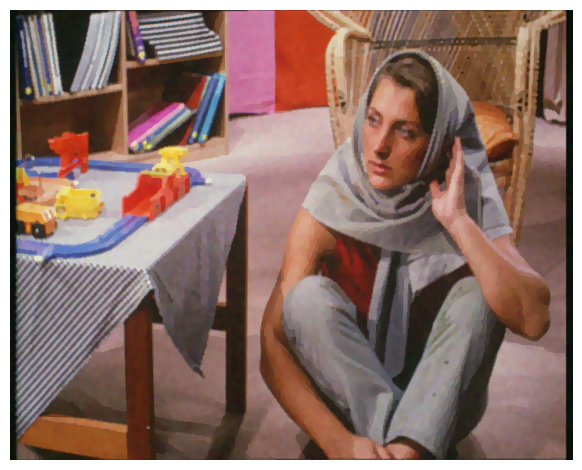

In [20]:
from PnP.pnp_solver import initialize_median_filter

params = config()
params.device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
for i, data in enumerate(test_loader):
    # fig, axes = plt.subplots(len(name), 3, figsize=(15, 5 * len(name)))

    clean_image, noisy_image, sigma = data  # dataset returns a tuple of (noisy_image, clean_image)
    b,c,m,n  = clean_image.shape
    i_str, j_str = 0, n-375
    i_stp, j_stp = 250, n-50
    # Move images to the same device as the model
    noisy_image = noisy_image.to(device=device, dtype=torch.float32)
    clean_image = clean_image.to(device=device, dtype=torch.float32)
    sigma = sigma.to(device=device, dtype=torch.float32)
    
    ## solver parameters
    # Declare linear restoration model
    _, _, h, w = noisy_image.shape
    # #inpainting
    # mask = (torch.rand(1, 1, h, w) <= 0.3).to(device)
    #gaussian blur
    kernel = gaussian_kernel(11,  1.6).to(device)
    params.linear_op = linear('blur', kernel)

    distorted_image = params.linear_op.A(noisy_image)
    # params.x0 = initialize_median_filter(params.b, params.mask)
    params.x0 = distorted_image
    # print(distorted_image.shape)
    # Algorithm parameters
    params.ker = kernel
    params.guide_iter=20
    params.b = distorted_image
    params.ground_truth = clean_image
    params.sigma = sigma
    params.L = 0.9
    params.tol = 1e-2
    params.device= device

    distorted_image_np = distorted_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
    clean_image_np = clean_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
    
    psnr_dist = calculate_psnr(clean_image, distorted_image)
    print(f'({psnr_dist:.2f}dB)')    
    plt.imshow(distorted_image_np)
    plt.axis('off')
    plt.tight_layout()
    plt.savefig(f'./out_{i}_n_.png')
    
    plt.imshow(clean_image_np)
    # plt.set_title(f'Clean Image')
    plt.axis('off')
    plt.tight_layout()
    plt.savefig(f'./out_{i}_c_.png')

    for j, denoiser in enumerate(denoisers):
        print(f'image:{i+1}/{len(test_loader)}, denoiser:{j+1}/{len(name)}')

        if name[j]=='BM3D':
            params.max_iter = 50
        else:
            params.max_iter = 100
        # Pass the noisy image through the model to get the denoised image
        
        # Declare regularizer
        params.regularizer = denoiser
        if name[j] =='BM3D':
            params.sigma = sigma*1.9
            params.sigma = sigma*1.9

        # create solver
        solver = IP_solver(params)

        with torch.no_grad():
            # restored_image, norm_xk, norm_error = solver.ISTA()
            restored_image = solver.ISTA()

        # Calculate PSNR of denoised image
        psnr = calculate_psnr(clean_image, restored_image)
        ssim = calculate_ssim(clean_image, restored_image)
        # calculate PSNR of noisy image
        # psnr_dist = calculate_psnr(clean_image, distorted_image)

        # Convert tensors to numpy arrays for plotting
        # distorted_image_np = distorted_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
        # clean_image_np = clean_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
        restored_image_np = restored_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)

        # # Plot the images
        # axes[j,0].imshow(distorted_image_np)
        # axes[j,0].set_title(f'Distorted Image({psnr_dist:.2f}dB)')
        # axes[j,0].axis('off')

        plt.imshow(restored_image_np)
        print(f'{name[j]}: Restored Image({psnr:.2f}dB, {ssim:.4f})')
        plt.axis('off')
        plt.tight_layout()
        plt.savefig(f'./out_{i}_r_{name[j]}.png')

        # axes[j,2].imshow(clean_image_np)
        # axes[j,2].set_title(f'Clean Image')
        # axes[j,2].axis('off')

    # plt.tight_layout()
    # plt.show()
    break

In [9]:
torch.functional.F.conv2d(clean_image[:,1:2], params.linear_op.oper.operator).shape

torch.Size([1, 1, 565, 709])

In [5]:
distorted_image.shape

torch.Size([1, 3, 1, 577, 721])

In [ ]:
import torch

def inf_median_filter_2d(image, kernel_radius=5):
    """
    Apply infinite median filter to a 2D image with specified kernel radius using PyTorch.
    
    Args:
        image (torch.Tensor): Input 2D image tensor
        kernel_radius (int): Radius of the kernel (should be positive)
    
    Returns:
        torch.Tensor: Filtered image with same shape as input
    """
    # Validate kernel radius
    assert kernel_radius > 0, 'Kernel radius should be greater than 0'
    if kernel_radius % 2 == 0:
        kernel_radius -= 1
    
    # Convert to float64 if not already
    image = image.to(torch.float64)
    
    # Pad with infinity
    padded_image = torch.nn.functional.pad(
        image, 
        (kernel_radius, kernel_radius, kernel_radius, kernel_radius),
        mode='constant',
        value=float('inf')
    )
    
    # Find infinity locations in original image
    infinity_indices = torch.where(torch.isinf(image))
    
    # Process each infinity pixel
    for row, col in zip(infinity_indices[0], infinity_indices[1]):
        # Convert to padded image coordinates
        row_padded = row + kernel_radius
        col_padded = col + kernel_radius
        
        # Extract patch
        patch = padded_image[
            row_padded - kernel_radius:row_padded + kernel_radius + 1,
            col_padded - kernel_radius:col_padded + kernel_radius + 1
        ]
        
        # Sort patch and handle special cases
        patch_flat = torch.sort(patch.flatten())[0]
        inf_indices = torch.where(torch.isinf(patch_flat))[0]
        
        # Skip if all values are infinity
        if len(inf_indices) == len(patch_flat):
            continue
            
        # Get valid (non-inf) values and compute median
        if len(inf_indices) == 0:
            valid_values = patch_flat
        else:
            valid_values = patch_flat[:inf_indices[0]]
            
        if len(valid_values) > 0:
            median = torch.median(valid_values)
            padded_image[row_padded, col_padded] = median
    
    # Extract and return the filtered region
    return padded_image[kernel_radius:-kernel_radius, kernel_radius:-kernel_radius]

def initialize_median_filter(observed_image, application_matrix, kernel_radius=1):
    """
    Initialize and apply median filter with increasing kernel size until all infinite values are removed.
    
    Args:
        observed_image (torch.Tensor): Original image tensor
        application_matrix (torch.Tensor): Binary matrix indicating valid pixels (1) and pixels to be filtered (0)
        kernel_radius (int): Initial kernel radius
    
    Returns:
        torch.Tensor: Filtered image with no infinite values
    """
    # Initialize image with infinities at masked locations
    initial_image = observed_image.clone()
    initial_image[application_matrix == 0] = float('inf')
    
    max_radius = min(initial_image.shape[0], initial_image.shape[1]) + 2
    
    # Iteratively apply filter with increasing kernel size
    while kernel_radius <= max_radius:
        initial_image = inf_median_filter_2d(initial_image, kernel_radius)
        
        if not torch.isinf(initial_image).any():
            break
            
        kernel_radius += 2
        
    return initial_image

def demo_median_filter():
    """
    Demonstrate usage of the PyTorch median filter implementation.
    """
    # Create sample image and application matrix
    image = torch.rand(10, 10)
    mask = torch.ones_like(image)
    mask[3:7, 3:7] = 0  # Create a region to be filtered
    
    # Apply filter
    filtered_image = initialize_median_filter(image, mask, kernel_radius=1)
    return filtered_image

# # Example usage with device handling
# def apply_median_filter(image, mask, kernel_radius=1, device='cpu'):
#     """
#     Apply median filter with device handling.
    
#     Args:
#         image (torch.Tensor): Input image
#         mask (torch.Tensor): Binary mask
#         kernel_radius (int): Initial kernel radius
#         device (str): Device to run the computation on
        
#     Returns:
#         torch.Tensor: Filtered image
#     """
#     # Move tensors to specified device
#     image = image.to(device)
#     mask = mask.to(device)
    
#     # Apply filter
#     filtered_image = initialize_median_filter(image, mask, kernel_radius)
    
#     return filtered_image

demo_median_filter()